# **<u>Price Action Predictor: Binary Classification of Weekly Direction in Financial Assets Using Machine Learning</u>**

A machine learning pipeline that predicts whether a financial asset will close higher or lower **5 trading days from now**, using technical indicators derived from historical OHLCV data as input features.

Rather than predicting the next day's direction — a highly noisy problem — this model takes a **weekly approach**, predicting whether the asset will close higher or lower 5 trading days from now. This horizon reduces daily noise while remaining actionable for a long-biased entry strategy.

The project's strategic focus is on maximizing the model's ability to correctly identify **up/flat weeks (class 1)**. In a monthly buy-timing strategy, a model that confidently and accurately flags favorable entry windows is more directly actionable than one focused on avoiding downturns — it allows an investor to time purchases around the model's most confident bullish signals, rather than passively waiting out predicted declines. For this reason, **Class-1 F1** is the key metric driving model selection and evaluation throughout this project.

# Libraries

In [1]:
#Data source
import yfinance as yf

#Data management
import pandas as pd
import numpy as np

#Time
import time
from datetime import datetime

#Data gathering
import requests

#GARCH (1,1)
from arch import arch_model

#Plots
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

#ML
from sklearn.ensemble import GradientBoostingClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics import classification_report
from sklearn.utils.class_weight import compute_sample_weight
import xgboost as xgb
from sklearn import set_config
from sklearn.dummy import DummyClassifier
from scipy.stats import binomtest

#Cross Validation 
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import make_scorer

#VIF (multicollinearity analysis)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Data Loading

In [2]:
import os

def load_data(ticker, csv_path=None, start='1990-01-01', end=None):
    """Loads daily OHLCV data for a ticker.

    If `csv_path` points to an existing file (e.g. exported from yfinance or Stooq),
    the data is read from disk; otherwise it is downloaded from Yahoo Finance.
    `end` lets the run be pinned to a fixed date so results stay reproducible.
    """
    if csv_path and os.path.exists(csv_path):
        df = pd.read_csv(csv_path, index_col=0, parse_dates=True)
        df.columns = [c.strip().title() for c in df.columns]
        df = df[['Open', 'High', 'Low', 'Close', 'Volume']].sort_index()
        source = f"local file '{csv_path}'"
    else:
        df = yf.download(ticker, start=start, end=end, auto_adjust=True)
        df.columns = df.columns.get_level_values(0)
        source = "Yahoo Finance"

    if end is not None:
        df = df[df.index < pd.Timestamp(end)]

    print(f"Data for {ticker} from {source}: {df.index[0].date()} to {df.index[-1].date()} ({len(df)} trading days)")
    return df

In [3]:
#END_DATE pins the run to the original analysis window (last session: 2026-07-24).
#Set END_DATE = None to use all data available today.
END_DATE = '2026-07-25'
data = load_data('SMH', csv_path='smh.csv', end=END_DATE)

[*********************100%***********************]  1 of 1 completed

Data for SMH from Yahoo Finance: 2000-06-05 to 2026-07-24 (6573 trading days)


In [4]:
#First 5 entries of the DataFrame
data.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2000-06-05,41.901115,42.670674,40.892729,41.396922,296800
2000-06-06,40.176239,42.564523,40.176239,41.821501,445600
2000-06-07,40.839649,41.184623,39.565898,40.653894,431000
2000-06-08,41.025410,41.980723,40.680435,41.954187,390400
2000-06-09,41.874577,42.033795,41.211164,41.715358,195000


# Data Standardization and Calculation of Metrics and Indicators (from yfinance DataFrame)

### DataFrame Standardization (snake_case)

In [5]:
#Snake case

data.columns = data.columns.str.lower()

data.columns = data.columns.str.replace(' ', '_')

print(data.columns)

Index(['close', 'high', 'low', 'open', 'volume'], dtype='str', name='Price')


#### Add Up/Down Binary Column

**Formula:** Daily Variation = ((current price - previous day close) / previous day close) * 100

- **1:** Price goes up or stays the same
- **0:** Price goes down

In [6]:
#1. Calculate the daily percentage change from close to close
data['daily_variation'] = ((data['close'] - data['close'].shift(1)) / data['close'].shift(1)) * 100

#Target: will the price be higher 5 trading days from now?
data['price_action_pred'] = (data['close'].shift(-5) > data['close']).astype(int)

data = data.dropna(subset=['price_action_pred'])

#3. Show first rows to verify
print(data[['close', 'daily_variation', 'price_action_pred']].head(10))

Price           close  daily_variation  price_action_pred
Date                                                     
2000-06-05  41.901115              NaN                  0
2000-06-06  40.176239        -4.116541                  1
2000-06-07  40.839649         1.651250                  0
2000-06-08  41.025410         0.454853                  0
2000-06-09  41.874577         2.069856                  0
2000-06-12  40.255852        -3.865651                  1
2000-06-13  41.954185         4.218849                  1
2000-06-14  40.149708        -4.301067                  1
2000-06-15  40.494678         0.859211                  1
2000-06-16  40.760048         0.655319                  1


In [7]:
#Verify count of up vs down days
print("Day count:")
print(data['price_action_pred'].value_counts())
print(f"\nDays that went up or stayed the same (1): {data['price_action_pred'].sum()}")
print(f"Days that went down (0): {len(data) - data['price_action_pred'].sum()}")

Day count:
price_action_pred
1    3621
0    2952
Name: count, dtype: int64

Days that went up or stayed the same (1): 3621
Days that went down (0): 2952


### Daily Return Metric (Log-Return)

In [8]:
#Daily return
#1. Calculate simple return first
simple_return = data['close'].pct_change()

#2. Apply log(1 + simple_return), handling cases where return <= -1
#If price went from positive to negative, simple return will be <= -1, which breaks the logarithm.
data['daily_return'] = np.where(simple_return > -1, np.log(1 + simple_return), np.nan)

### Intraday Return Metric (Log-Return | Return within market hours)

In [9]:
#Intraday return (log-return | return within market hours)
data['intraday_return'] = np.log(data['close']/data['open']).shift(1)

### Overnight Gap Metric

In [10]:
data['overnight_gap'] = (np.log(data['open'] / data['close'].shift(1))).shift(1)

### Close Location Value (CLV)

The `close_location` metric mathematically calculates how close the price closed to the session's high (value of 1.0) or low (value of 0.0), indicating in a single number whether buyers or sellers were in control at the end of the previous day.



In [11]:
data['close_location'] = ((data['close'] - data['low']) / (data['high'] - data['low'])).shift(1)

### Opening Position Metric

Measures the position of the current open within the previous day's range.

In [12]:
data['open_location'] = ((data['open'] - data['low'].shift(1)) / (data['high'].shift(1) - data['low'].shift(1))).shift(1)

### Parkinson Volatility Metric

An advanced mathematical estimator that measures volatility using high and low prices. It is significantly more precise for Machine Learning models because it ignores overnight gaps and focuses on the actual intraday market movement.

In [13]:
data['parkinson_volatility'] = (np.sqrt((1 / (4 * np.log(2))) * (np.log(data['high'] / data['low']) ** 2))).shift(1)

### RSI (14 Days)

Measures whether the asset is overbought or oversold. Oscillates between 0 and 100. Above 70 the market is overbought (possible drop), below 30 it is oversold (possible rebound).

In [14]:
delta = data["close"].diff()
g = delta.clip(lower=0).ewm(com=13, min_periods=14).mean()
p = (-delta).clip(lower=0).ewm(com=13, min_periods=14).mean()
data["rsi_14"] = (100 - 100 / (1 + g / p.replace(0, np.nan))).shift(1)

### MACD Histogram

Measures buying or selling momentum and its acceleration. When the histogram crosses from negative to positive it anticipates a bullish change, and vice versa. It is more reactive than moving averages alone.

In [15]:
ema12 = data["close"].ewm(span=12, adjust=False).mean()
ema26 = data["close"].ewm(span=26, adjust=False).mean()
macd  = ema12 - ema26
data["macd_hist"] = (macd - macd.ewm(span=9, adjust=False).mean()).shift(1)

### Distance to SMA 20

How far the price is from its 20-session moving average, expressed as a percentage. Positive = price above the average, negative = below. Captures short-term deviations.

In [16]:
sma20 = data["close"].rolling(20).mean()
data["dist_sma20"] = ((data["close"] - sma20) / sma20 * 100).shift(1)

### Rate of Change (5 Days)

The accumulated return over the last 5 trading days. Captures short-term momentum. If the price has risen consistently for 5 days, the model can learn whether that trend continues or reverts.

In [17]:
data["roc_5"] = data["close"].pct_change(5).shift(1)

### Bollinger Band Position

Indicates where the price is within its recent statistical range. Close to 1 means the price is at the upper band (expensive relative to its recent history), close to -1 means it is at the lower band (cheap).

In [18]:
sma20 = data["close"].rolling(20).mean()
std20 = data["close"].rolling(20).std()
data["bollinger_pos"] = ((data["close"] - sma20) / (2 * std20)).shift(1)

### Volume Ratio

Compares the current day's volume against its 20-day average. A ratio above 1.5 suggests institutional participation. High volume on down days signals distribution (selling pressure), while high volume on up days signals accumulation — a critical indicator for identifying meaningful price floors.

In [19]:
data["volume_ratio"] = (data["volume"] / data["volume"].rolling(20).mean()).shift(1)

### Distance to SMA 50

Measures how far the price is from its 50-session moving average, expressed as a percentage. The SMA 50 is the primary medium-term reference used by institutional traders. Price bouncing off the SMA 50 from below is one of the most widely traded buy setups in equity markets.

In [20]:
sma50 = data["close"].rolling(50).mean()
data["dist_sma50"] = ((data["close"] - sma50) / sma50 * 100).shift(1)

### 60-Day Return Quantile

Ranks the current daily return within the distribution of the last 60 trading days, expressed as a percentile between 0 and 1. Values near 0 indicate an unusually large down move relative to recent history — a stochastic signal used in systematic funds to detect statistically extreme moves that tend to revert.

In [21]:
data["return_quantile_60d"] = (
    data["daily_return"]
    .rolling(60)
    .apply(lambda x: pd.Series(x).rank(pct=True).iloc[-1])
    .shift(1)
)

### GARCH(1,1) Conditional Volatility

A stochastic volatility model that captures volatility clustering — the well-documented tendency for large price moves to be followed by more large moves, and calm periods to be followed by more calm periods. Unlike Parkinson volatility, which only measures *realized* volatility from a single day's range, GARCH estimates the *conditional* (forward-looking) volatility based on the recent history of shocks, making it a genuinely probabilistic feature rather than a simple descriptive statistic.

**Estimation is walk-forward, not global.** Fitting GARCH once on the entire return history and slicing the result into train/validation/test would let each period's volatility estimate be informed by parameters (ω, α, β) that were shaped in part by future returns — a look-ahead bias that global-fit models are especially prone to, since they optimize a single likelihood over every observation handed to them, not row-by-row. To avoid this, the model is refit periodically on an **expanding window** (using only returns available up to that point) and used to *forecast* volatility forward until the next refit — so every value assigned to a given date comes from a model that had no knowledge of that date's future.

In [22]:

MIN_TRAIN_OBS = 250      #~1 trading year minimum before first fit
REFIT_EVERY   = 21       #trading days between refits (~monthly)

returns_pct = (data['daily_return'].dropna()) * 100
dates = returns_pct.index

garch_vol = pd.Series(index=dates, dtype=float)

start = MIN_TRAIN_OBS
while start < len(dates):
    
    train_window = returns_pct.iloc[:start]

    horizon = min(REFIT_EVERY, len(dates) - start)

    garch = arch_model(train_window, vol='Garch', p=1, q=1, dist='normal')
    garch_fit = garch.fit(disp='off')

    
    fc = garch_fit.forecast(horizon=horizon, reindex=False)
    forecast_vol = np.sqrt(fc.variance.values[-1])  

    target_dates = dates[start:start + horizon]
    garch_vol.loc[target_dates] = forecast_vol

    start += REFIT_EVERY


data['garch_vol'] = garch_vol.reindex(data.index).shift(1)

print(f"GARCH walk-forward complete: {len(dates) // REFIT_EVERY} refits, "
      f"first {MIN_TRAIN_OBS} rows have no forecast (expected, will be dropped by dropna).")

GARCH walk-forward complete: 312 refits, first 250 rows have no forecast (expected, will be dropped by dropna).


### NaN Handling and Data Cleaning 

In [23]:
print(f"Rows before dropna: {len(data)}")
data = data.dropna()
print(f"Rows after dropna: {len(data)}")

Rows before dropna: 6573
Rows after dropna: 6321


**Note:** the last 5 rows will have `NaN` in `price_action_pred` since there's no future price to compare against. These are naturally removed by the `dropna()` step above, but it's worth tracking separately for clarity.

In [24]:
print(f"Infinite values found: {np.isinf(data.select_dtypes(include=[np.number])).sum().sum()}")
data = data.replace([np.inf, -np.inf], np.nan).dropna()

Infinite values found: 0


In [25]:
data

Price,close,high,low,open,volume,daily_variation,price_action_pred,daily_return,intraday_return,overnight_gap,...,parkinson_volatility,rsi_14,macd_hist,dist_sma20,roc_5,bollinger_pos,volume_ratio,dist_sma50,return_quantile_60d,garch_vol
Date,,,,,,,,,,,,,,,,,,,,,
2001-06-05,21.186733,21.437238,20.380023,20.401252,3382400,6.260654,0,0.060725,-0.011434,-0.002103,...,0.020213,45.340411,-0.271189,-4.846819,-0.069177,-0.505432,0.609905,-0.395792,0.466667,4.075470
2001-06-06,21.038124,21.420250,20.656000,21.016895,3234400,-0.701426,0,-0.007039,0.037779,0.022946,...,0.030373,52.741696,-0.172366,1.151384,0.035915,0.120363,0.787994,5.813151,0.883333,4.098790
2001-06-07,22.647303,22.660040,20.974443,20.974443,9018200,7.648869,0,0.073705,0.001010,-0.008049,...,0.021819,51.841703,-0.112007,0.590734,0.099889,0.062518,0.744939,4.981460,0.483333,4.120614
2001-06-08,21.917017,22.630318,21.696233,22.375568,3701400,-3.224603,0,-0.032777,0.076736,-0.003032,...,0.046422,59.834235,0.033513,7.820750,0.159565,0.774170,2.029819,12.746680,0.916667,4.141045
2001-06-11,21.199472,21.611319,20.953213,21.611319,3718800,-3.273915,0,-0.033287,-0.020706,-0.012071,...,0.025315,55.345072,0.075406,4.057895,0.084454,0.396294,0.829983,8.774443,0.250000,4.160179
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-07-20,558.830017,572.770020,557.239990,568.780029,6962600,0.413273,0,0.004124,0.015555,-0.037574,...,0.033294,41.151310,-7.767161,-8.903930,-0.089194,-0.918759,1.810965,-6.831046,0.233333,3.864654
2026-07-21,584.080017,586.000000,572.049988,580.960022,7129800,4.518369,0,0.044193,-0.017648,0.021773,...,0.016508,41.727135,-7.935680,-7.764648,-0.045746,-0.799219,0.581127,-6.474406,0.433333,3.856853
2026-07-22,586.909973,592.010010,571.349976,571.349976,5249700,0.484515,0,0.004833,0.005356,0.038837,...,0.014470,47.769392,-6.009028,-2.917476,-0.027036,-0.340809,0.597359,-2.392263,0.900000,3.849083


# EDA and Data Interpretation

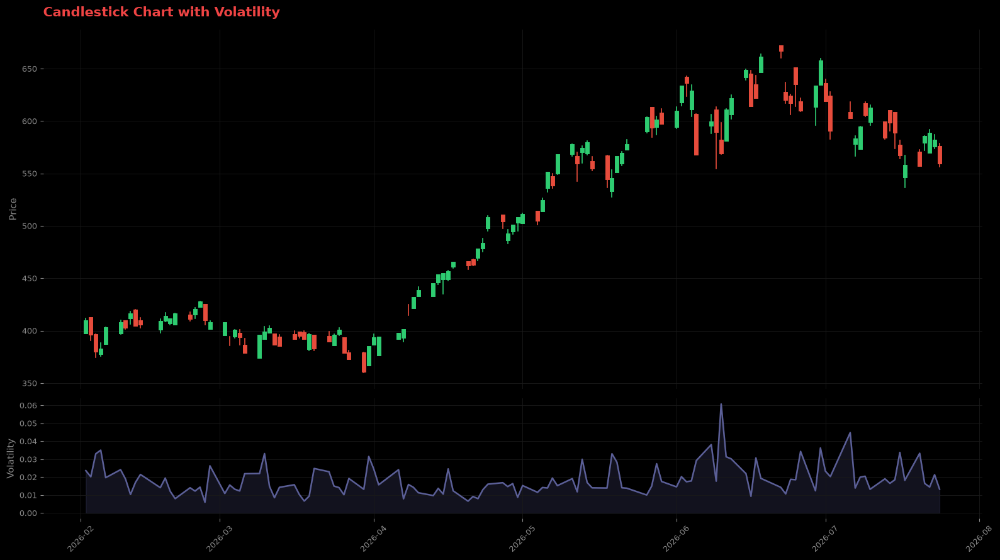

In [26]:
plot_data = data.tail(120).copy()
plot_data['color'] = np.where(plot_data['close'] >= plot_data['open'], '#2ECC71', '#E74C3C')

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(16, 9),
    gridspec_kw={'height_ratios': [3, 1]},
    sharex=True
)
fig.patch.set_facecolor("#000000")
ax1.set_facecolor("#000000")
ax2.set_facecolor("#000000")

#Top: Candlestick
for idx, row in plot_data.iterrows():
    ax1.plot([idx, idx], [row['low'], row['high']], color=row['color'], linewidth=1.2)
    ax1.plot([idx, idx], [row['open'], row['close']], color=row['color'], linewidth=5)

ax1.set_title('Candlestick Chart with Volatility', fontsize=15, fontweight='bold', color="#EF4444", pad=15, loc='left')
ax1.set_ylabel('Price', fontsize=11, color="#888888")
ax1.tick_params(axis='y', labelsize=9, colors="#888888")
ax1.grid(color="#1a1a1a", linewidth=0.6)
for spine in ax1.spines.values():
    spine.set_visible(False)

#Bottom: Volatility as line
ax2.plot(plot_data.index, plot_data['parkinson_volatility'], color='#5B5F97', linewidth=1.8)
ax2.fill_between(plot_data.index, plot_data['parkinson_volatility'], alpha=0.20, color='#5B5F97')
ax2.set_ylabel('Volatility', fontsize=11, color="#888888")
ax2.tick_params(axis='y', labelsize=9, colors="#888888")
ax2.tick_params(axis='x', labelsize=9, colors="#888888")
ax2.grid(color="#1a1a1a", linewidth=0.6)
for spine in ax2.spines.values():
    spine.set_visible(False)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The chart above shows the last 120 trading days of price action alongside realized volatility. Blue candles represent up days, red candles represent down days, with the wick showing the full high-low range and the body showing the open-close range. The volatility panel below tracks Parkinson volatility over the same period, making it easy to spot whether sharp price moves coincide with volatility spikes — a pattern consistent with volatility clustering.

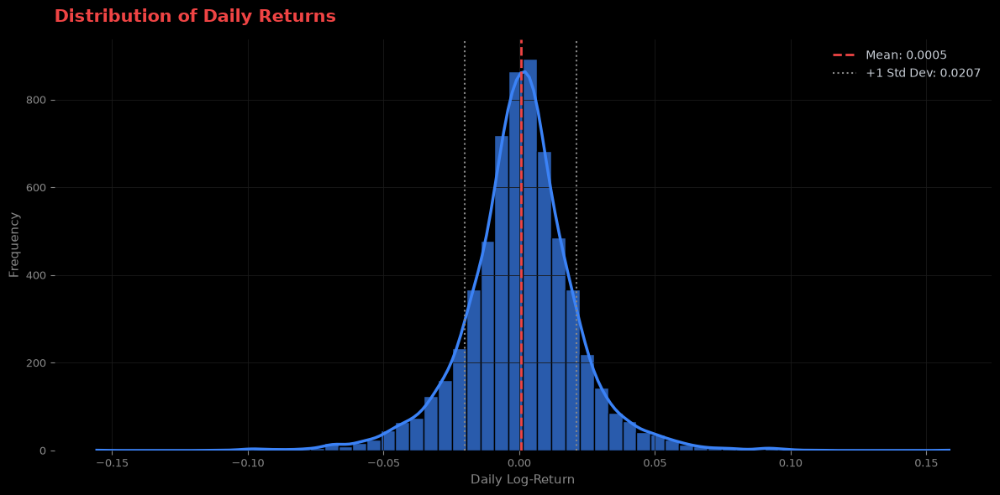

In [27]:
fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor("#000000")
ax.set_facecolor("#000000")

sns.histplot(
    data=data, x='daily_return',
    bins=60, kde=True,
    color='#3B82F6', edgecolor='#000000', alpha=0.7,
    line_kws={'linewidth': 2.5, 'color': '#EF4444'},
    ax=ax
)

mean_ret = data['daily_return'].mean()
std_ret  = data['daily_return'].std()

ax.axvline(mean_ret, color='#EF4444', linestyle='--', linewidth=2, label=f'Mean: {mean_ret:.4f}')
ax.axvline(mean_ret + std_ret, color='#888888', linestyle=':', linewidth=1.5, label=f'+1 Std Dev: {std_ret:.4f}')
ax.axvline(mean_ret - std_ret, color='#888888', linestyle=':', linewidth=1.5)

ax.set_title('Distribution of Daily Returns', fontsize=15, fontweight='bold', color="#EF4444", pad=15, loc='left')
ax.set_xlabel('Daily Log-Return', fontsize=11, color="#888888")
ax.set_ylabel('Frequency', fontsize=11, color="#888888")
ax.tick_params(labelsize=9, colors="#888888")
ax.grid(color="#1a1a1a", linewidth=0.6)
for spine in ax.spines.values():
    spine.set_visible(False)

legend = ax.legend(fontsize=10, loc='upper right', frameon=False)
for text in legend.get_texts():
    text.set_color("#c8ced6")

plt.tight_layout()
plt.show()

The histogram shows the distribution of daily log-returns, overlaid with a kernel density estimate (KDE) to visualize the underlying shape. The dashed lines mark the mean and one standard deviation in each direction. Most returns cluster tightly around zero, but the presence of values well beyond ±1 standard deviation suggests a fat-tailed distribution — a well-documented characteristic of financial returns that deviates from a normal distribution and has important implications for risk modeling.

In [28]:
corr_features = [
    'rsi_14', 'macd_hist', 'dist_sma20', 'dist_sma50',
    'volume_ratio', 'bollinger_pos', 'roc_5',
    'return_quantile_60d', 'garch_vol'
]

vol_correlations = data[corr_features + ['parkinson_volatility']].corr()['parkinson_volatility'].drop('parkinson_volatility')
vol_correlations = vol_correlations.sort_values(key=abs, ascending=False)

print("Correlation with Parkinson Volatility:")
print(vol_correlations)

Correlation with Parkinson Volatility:
Price
garch_vol              0.612503
dist_sma50            -0.381462
rsi_14                -0.359092
volume_ratio           0.334192
dist_sma20            -0.312073
bollinger_pos         -0.277146
roc_5                 -0.201817
macd_hist             -0.136920
return_quantile_60d   -0.048434
Name: parkinson_volatility, dtype: float64


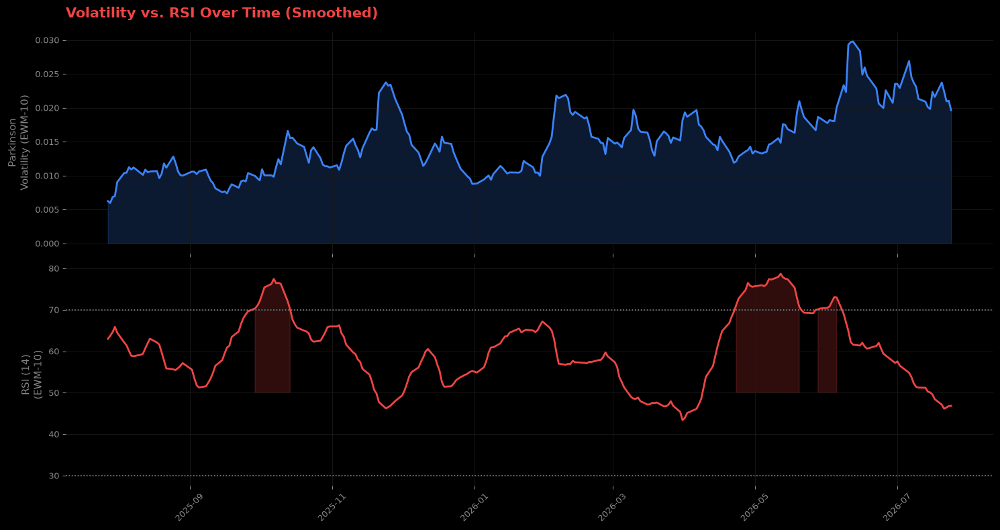

In [29]:
plot_data = data.tail(250).copy()
plot_data['vol_smooth'] = plot_data['parkinson_volatility'].ewm(span=10, adjust=False).mean()
plot_data['rsi_smooth'] = plot_data['rsi_14'].ewm(span=10, adjust=False).mean()

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(15, 8),
    sharex=True,
    gridspec_kw={'height_ratios': [1, 1]}
)
fig.patch.set_facecolor("#000000")
ax1.set_facecolor("#000000")
ax2.set_facecolor("#000000")

#Top: Smoothed Volatility
ax1.plot(plot_data.index, plot_data['vol_smooth'], color='#3B82F6', linewidth=2)
ax1.fill_between(plot_data.index, plot_data['vol_smooth'], alpha=0.20, color='#3B82F6')
ax1.set_ylabel('Parkinson\nVolatility (EWM-10)', fontsize=11, color="#888888")
ax1.set_title('Volatility vs. RSI Over Time (Smoothed)', fontsize=15, fontweight='bold', color="#EF4444", pad=15, loc='left')
ax1.tick_params(labelsize=9, colors="#888888")
ax1.grid(color="#1a1a1a", linewidth=0.6)
for spine in ax1.spines.values():
    spine.set_visible(False)

#Bottom: Smoothed RSI
ax2.plot(plot_data.index, plot_data['rsi_smooth'], color='#EF4444', linewidth=2)
ax2.axhline(70, color='#888888', linestyle=':', linewidth=1.2)
ax2.axhline(30, color='#888888', linestyle=':', linewidth=1.2)
ax2.fill_between(plot_data.index, plot_data['rsi_smooth'], 50, where=(plot_data['rsi_smooth'] >= 70), color='#EF4444', alpha=0.20)
ax2.fill_between(plot_data.index, plot_data['rsi_smooth'], 50, where=(plot_data['rsi_smooth'] <= 30), color='#3B82F6', alpha=0.20)
ax2.set_ylabel('RSI (14)\n(EWM-10)', fontsize=11, color="#888888")
ax2.tick_params(labelsize=9, colors="#888888")
ax2.grid(color="#1a1a1a", linewidth=0.6)
for spine in ax2.spines.values():
    spine.set_visible(False)

plt.xticks(rotation=45, color="#888888")
plt.tight_layout()
plt.show()

RSI showed the strongest relationship, suggesting that volatility tends to rise when the asset reaches overbought or oversold extremes.

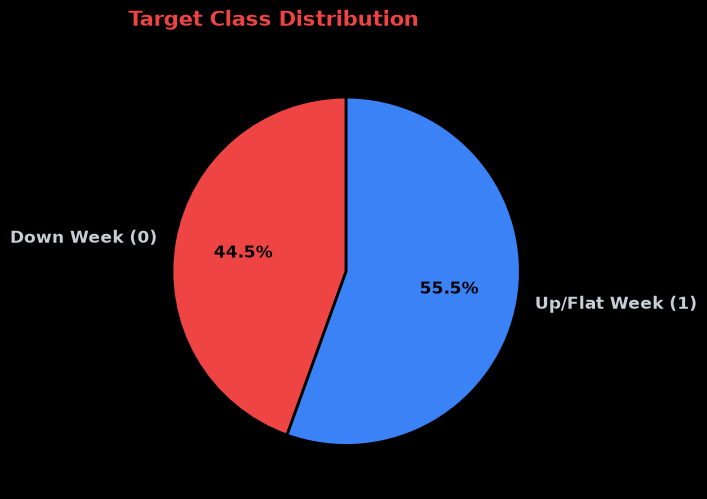

In [30]:
#Data prep
counts = data['price_action_pred'].value_counts()
pct = data['price_action_pred'].value_counts(normalize=True) * 100

labels = ['Down Week (0)', 'Up/Flat Week (1)']
values = [counts.get(0, 0), counts.get(1, 0)]
percentages = [pct.get(0, 0), pct.get(1, 0)]

fig, ax = plt.subplots(figsize=(7, 7))
fig.patch.set_facecolor("#000000")
ax.set_facecolor("#000000")

wedges, texts, autotexts = ax.pie(
    values, labels=labels, colors=['#EF4444', '#3B82F6'],
    autopct='%1.1f%%', startangle=90,
    wedgeprops=dict(edgecolor='#000000', linewidth=2),
    textprops={'fontsize': 12, 'fontweight': 'bold', 'color': '#c8ced6'}
)

for autotext in autotexts:
    autotext.set_color('#000000')
    autotext.set_fontsize(12)

ax.set_title('Target Class Distribution', fontsize=15, fontweight='bold', color="#EF4444", pad=20, loc='left')
plt.tight_layout()
plt.show()

# Correlation Analysis

 ### Multicollinearity Analysis (VIF) — Automated

Rather than manually inspecting VIF results and dropping features one at a time, this step automates the process: the feature with the highest VIF is dropped iteratively, and VIF is recalculated after each removal, until all remaining features fall below the standard threshold of 10. This makes the feature selection process reproducible and asset-agnostic, since the specific features dropped will adapt automatically to whichever asset's data is being analyzed.

In [31]:
def auto_drop_vif(df, exclude_cols, threshold=10):
    """
    Iteratively drops the feature with the highest VIF until all 
    remaining features are below the threshold.
    """
    X_current = df.drop(columns=[col for col in exclude_cols if col in df.columns])
    dropped_features = []
    
    while True:
        X_vif_input = add_constant(X_current)
        
        vif_values = pd.Series(
            [variance_inflation_factor(X_vif_input.values, i+1) for i in range(len(X_current.columns))],
            index=X_current.columns
        )
        
        max_vif = vif_values.max()
        
        if max_vif <= threshold:
            break
        
        feature_to_drop = vif_values.idxmax()
        dropped_features.append((feature_to_drop, max_vif))
        X_current = X_current.drop(columns=[feature_to_drop])
        
        print(f"Dropped '{feature_to_drop}' (VIF = {max_vif:.2f})")
    
    print(f"\nFinal feature set ({len(X_current.columns)} features), all VIF <= {threshold}:")
    print(X_current.columns.tolist())
    
    return X_current.columns.tolist(), dropped_features


columns_exclude = [
    'open', 'high', 'low', 'close', 'volume',
    'price_action_pred', 'daily_variation'
]

#Establish the train boundary BEFORE running VIF, so only training rows are used
n = len(data)
train_end = int(n * 0.70)
train_data_for_vif = data.iloc[:train_end]

print(f"Running VIF on training data only: rows 0 to {train_end} ({train_end} of {n} total rows)")
features, dropped_log = auto_drop_vif(train_data_for_vif, columns_exclude, threshold=10)

Running VIF on training data only: rows 0 to 4424 (4424 of 6321 total rows)
Dropped 'dist_sma20' (VIF = 14.07)
Dropped 'rsi_14' (VIF = 10.81)

Final feature set (13 features), all VIF <= 10:
['daily_return', 'intraday_return', 'overnight_gap', 'close_location', 'open_location', 'parkinson_volatility', 'macd_hist', 'roc_5', 'bollinger_pos', 'volume_ratio', 'dist_sma50', 'return_quantile_60d', 'garch_vol']


# Model (validating and tunning)

### Defining Predictor and Target Variables

In [32]:
#Predictor variables based on correlation analysis
X = data[features]

#Define target variable
y = data['price_action_pred']

#Verify the dimensions of our matrices
print(f"X (Features) dimensions: {X.shape}")
print(f"y (Target) dimensions: {y.shape}")

X (Features) dimensions: (6321, 13)
y (Target) dimensions: (6321,)


### Model Testing Split

In financial data, you can't shuffle everything randomly because the order of time is sacred: what happens today depends directly on what happened yesterday. We use a **sequential split** instead of a random one to protect that chain of cause and effect, preventing the model from cheating by "traveling to the future" to guess the past. This way, the algorithm doesn't look for an abstract, general rule, but instead learns to recognize how patterns evolve and propagate through history, training under the exact same conditions it will face in the real market.

In [33]:
#IMPORTANT: Since this is time series data, we do NOT use shuffle (randomness).
#We split the matrix respecting strict chronological order: 70% train, 15% validation, 15% test.

#Small gap between splits to avoid leakage from the 5-day-ahead target overlap
gap = 5

n = len(X)
train_end = int(n * 0.70)
val_end   = int(n * 0.85)

X_train = X.iloc[:train_end - gap]
X_val   = X.iloc[train_end:val_end - gap]
X_test  = X.iloc[val_end:]

y_train = y.iloc[:train_end - gap]
y_val   = y.iloc[train_end:val_end - gap]
y_test  = y.iloc[val_end:]

print(f"Training:   X={X_train.shape}, y={y_train.shape}")
print(f"Validation: X={X_val.shape}, y={y_val.shape}")
print(f"Test:       X={X_test.shape}, y={y_test.shape}")

Training:   X=(4419, 13), y=(4419,)
Validation: X=(943, 13), y=(943,)
Test:       X=(949, 13), y=(949,)


 ### Models to Test

In [34]:
sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

#Cat boosting
cat_model = CatBoostClassifier(
    iterations=150,
    learning_rate=0.05,
    depth=4,
    random_state=5,
    verbose=False
)


#Gradient Boosting
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=4
)


#XGBoost
sample_weights_xgb = compute_sample_weight(class_weight='balanced', y=y_train) #Building up the balanced weights to represent more the 0 class. 
xgb_model = xgb.XGBClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=6,
    n_jobs=-1
)

### Model Training

In [35]:
#Cat boosting
cat_model.fit(X_train, y_train, sample_weight=sample_weights)

#Gradient Boosting
gb_model.fit(X_train, y_train, sample_weight=sample_weights)


#XGBoost
xgb_model.fit(X_train, y_train, sample_weight=sample_weights_xgb)

print("Models trained successfully.")

Models trained successfully.


### Model Evaluation on the Validation Split

In [36]:
models = {
    "Cat Boosting": cat_model,
    "Gradient Boosting": gb_model,
    "XGBoost": xgb_model
}

for name, model in models.items():
    y_pred_val = model.predict(X_val)

    print(f"\n{'='*70}")
    print(f" {name} - Baseline (default parameters on validation set)")
    print(f"{'='*70}")
    print(classification_report(y_val, y_pred_val, target_names=["Down Week (0)", "Up/Flat Week (1)"]))


 Cat Boosting - Baseline (default parameters on validation set)
                  precision    recall  f1-score   support

   Down Week (0)       0.42      0.49      0.45       398
Up/Flat Week (1)       0.57      0.49      0.53       545

        accuracy                           0.49       943
       macro avg       0.49      0.49      0.49       943
    weighted avg       0.51      0.49      0.50       943


 Gradient Boosting - Baseline (default parameters on validation set)
                  precision    recall  f1-score   support

   Down Week (0)       0.41      0.48      0.45       398
Up/Flat Week (1)       0.57      0.50      0.53       545

        accuracy                           0.49       943
       macro avg       0.49      0.49      0.49       943
    weighted avg       0.50      0.49      0.50       943


 XGBoost - Baseline (default parameters on validation set)
                  precision    recall  f1-score   support

   Down Week (0)       0.41      0.42      0

### Hyperparameter Tuning with TimeSeriesSplit

Rather than relying on a single fixed validation window, hyperparameters are tuned using `TimeSeriesSplit`, which creates multiple expanding train/validation folds across the training period. Each fold trains on an increasing window of past data and validates on the immediately following period, then the process repeats further forward in time. This gives a more robust estimate of which hyperparameters generalize well across different historical periods, rather than risking a hyperparameter choice that simply performed well by chance on one specific validation slice. The held-out test set remains completely untouched throughout this process, reserved for a single final evaluation.

### Hyperparameter Sensitivity Analysis (Pre-Tuning Diagnostic)

Before defining the final hyperparameter grids, each model's sensitivity to its most influential parameters is examined individually, holding other settings at reasonable defaults. This identifies the approximate region where each model performs best, allowing the subsequent grid search to be tightly focused around genuine optima rather than guessed ranges — improving both the efficiency and the methodological rigor of the tuning process.

In [37]:
set_config(enable_metadata_routing=True)

In [38]:

#SCORER: Class-1 F1 — balances precision and recall for the
#"up/flat week" class, the signal the buy-timing strategy relies on.

scorer = make_scorer(f1_score, pos_label=1, zero_division=0)
scorer.set_score_request(sample_weight=False)

#5 expanding folds across the training set only (test set stays untouched)
tscv = TimeSeriesSplit(n_splits=5, gap=5)

In [39]:
def sweep_param(model_class, param_name, param_range, fixed_params, sample_weight_arr=None):
    scores = []
    for val in param_range:
        params = {**fixed_params, param_name: val}
        estimator = model_class(**params)

        if sample_weight_arr is not None and hasattr(estimator, 'set_fit_request'):
            #Models that support sklearn's metadata routing: use GridSearchCV as before
            estimator.set_fit_request(sample_weight=True)
            search = GridSearchCV(
                estimator, {param_name: [val]}, scoring=scorer,
                cv=tscv, n_jobs=-1, error_score='raise'
            )
            search.fit(X_train, y_train, sample_weight=sample_weight_arr)
            scores.append(search.best_score_)

        else:
            #Models without routing support (e.g. CatBoost): manual CV over the
            #same tscv splits, calling .fit() directly so sample_weight bypasses
            #GridSearchCV's routing check entirely.
            fold_scores = []
            for train_idx, val_idx in tscv.split(X_train):
                X_tr, X_va = X_train.iloc[train_idx], X_train.iloc[val_idx]
                y_tr, y_va = y_train.iloc[train_idx], y_train.iloc[val_idx]
                sw_tr = sample_weight_arr[train_idx] if sample_weight_arr is not None else None

                m = model_class(**params)
                if sw_tr is not None:
                    m.fit(X_tr, y_tr, sample_weight=sw_tr)
                else:
                    m.fit(X_tr, y_tr)

                y_pred_va = m.predict(X_va)
                fold_scores.append(f1_score(y_va, y_pred_va, pos_label=1, zero_division=0))

            scores.append(np.mean(fold_scores))

    return scores

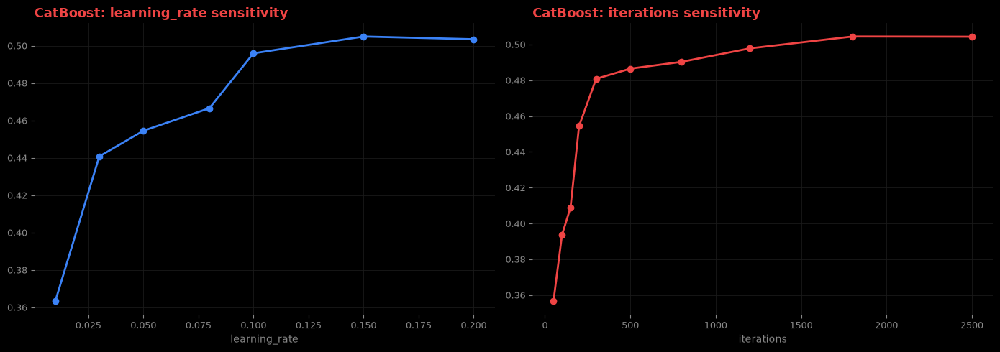

In [40]:
cat_lr_range = [0.01, 0.03, 0.05, 0.08, 0.1, 0.15, 0.2]
cat_lr_scores = sweep_param(
    CatBoostClassifier, 'learning_rate', cat_lr_range,
    {'iterations': 200, 'depth': 4, 'random_state': 5, 'verbose': False},
    sample_weight_arr=sample_weights
)

cat_iter_range = [50, 100, 150, 200, 300, 500, 800, 1200, 1800, 2500]
cat_iter_scores = sweep_param(
    CatBoostClassifier, 'iterations', cat_iter_range,
    {'learning_rate': 0.05, 'depth': 4, 'random_state': 5, 'verbose': False},
    sample_weight_arr=sample_weights
)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor("#000000")

for ax in axes:
    ax.set_facecolor("#000000")
    ax.tick_params(labelsize=9, colors="#888888")
    ax.grid(color="#1a1a1a", linewidth=0.6)
    for spine in ax.spines.values():
        spine.set_visible(False)

axes[0].plot(cat_lr_range, cat_lr_scores, marker='o', color='#3B82F6', linewidth=2)
axes[0].set_title('CatBoost: learning_rate sensitivity', fontsize=13, fontweight='bold', color="#EF4444", loc='left')
axes[0].set_xlabel('learning_rate', fontsize=10, color="#888888")

axes[1].plot(cat_iter_range, cat_iter_scores, marker='o', color='#EF4444', linewidth=2)
axes[1].set_title('CatBoost: iterations sensitivity', fontsize=13, fontweight='bold', color="#EF4444", loc='left')
axes[1].set_xlabel('iterations', fontsize=10, color="#888888")

plt.tight_layout()
plt.show()

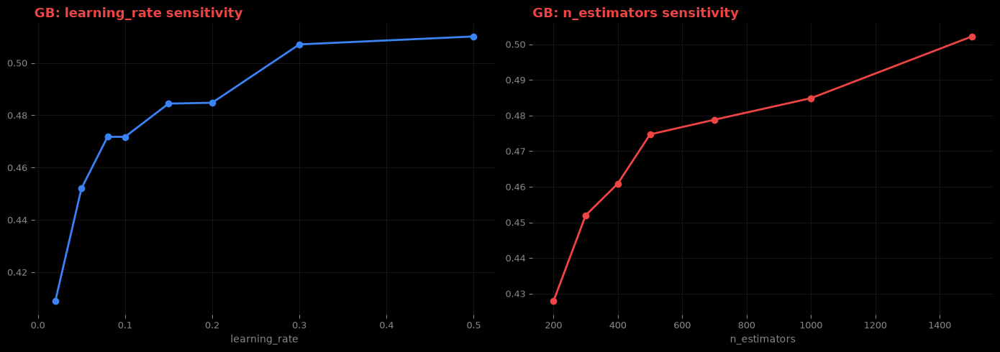

In [41]:
gb_lr_range = [0.02, 0.05, 0.08, 0.1, 0.15, 0.2, 0.3, 0.5]
gb_lr_scores = sweep_param(
    GradientBoostingClassifier, 'learning_rate', gb_lr_range,
    {'n_estimators': 300, 'max_depth': 2, 'min_samples_leaf': 30, 'random_state': 4},
    sample_weight_arr=sample_weights
)

gb_n_range = [200, 300, 400, 500, 700, 1000, 1500]
gb_n_scores = sweep_param(
    GradientBoostingClassifier, 'n_estimators', gb_n_range,
    {'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 30, 'random_state': 4},
    sample_weight_arr=sample_weights
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor("#000000")

for ax in axes:
    ax.set_facecolor("#000000")
    ax.tick_params(labelsize=9, colors="#888888")
    ax.grid(color="#1a1a1a", linewidth=0.6)
    for spine in ax.spines.values():
        spine.set_visible(False)

axes[0].plot(gb_lr_range, gb_lr_scores, marker='o', color='#3B82F6', linewidth=2)
axes[0].set_title('GB: learning_rate sensitivity', fontsize=13, fontweight='bold', color="#EF4444", loc='left')
axes[0].set_xlabel('learning_rate', fontsize=10, color="#888888")

axes[1].plot(gb_n_range, gb_n_scores, marker='o', color='#EF4444', linewidth=2)
axes[1].set_title('GB: n_estimators sensitivity', fontsize=13, fontweight='bold', color="#EF4444", loc='left')
axes[1].set_xlabel('n_estimators', fontsize=10, color="#888888")

plt.tight_layout()
plt.show()

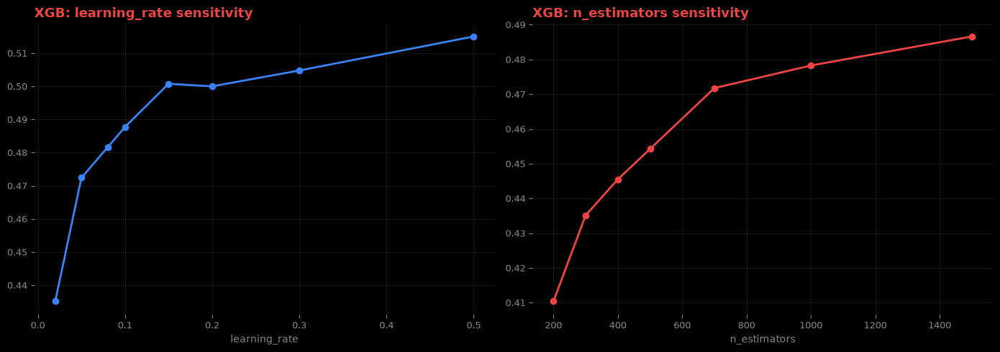

In [42]:
xgb_lr_range = [0.02, 0.05, 0.08, 0.1, 0.15, 0.2, 0.3, 0.5]
xgb_lr_scores = sweep_param(
    xgb.XGBClassifier, 'learning_rate', xgb_lr_range,
    {'n_estimators': 300, 'max_depth': 3, 'min_child_weight': 5, 'eval_metric': 'logloss', 'random_state': 6, 'n_jobs': -1},
    sample_weight_arr=sample_weights_xgb
)

xgb_n_range = [200, 300, 400, 500, 700, 1000, 1500]
xgb_n_scores = sweep_param(
    xgb.XGBClassifier, 'n_estimators', xgb_n_range,
    {'learning_rate': 0.02, 'max_depth': 3, 'min_child_weight': 5, 'eval_metric': 'logloss', 'random_state': 6, 'n_jobs': -1},
    sample_weight_arr=sample_weights_xgb
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor("#000000")

for ax in axes:
    ax.set_facecolor("#000000")
    ax.tick_params(labelsize=9, colors="#888888")
    ax.grid(color="#1a1a1a", linewidth=0.6)
    for spine in ax.spines.values():
        spine.set_visible(False)

axes[0].plot(xgb_lr_range, xgb_lr_scores, marker='o', color='#3B82F6', linewidth=2)
axes[0].set_title('XGB: learning_rate sensitivity', fontsize=13, fontweight='bold', color="#EF4444", loc='left')
axes[0].set_xlabel('learning_rate', fontsize=10, color="#888888")

axes[1].plot(xgb_n_range, xgb_n_scores, marker='o', color='#EF4444', linewidth=2)
axes[1].set_title('XGB: n_estimators sensitivity', fontsize=13, fontweight='bold', color="#EF4444", loc='left')
axes[1].set_xlabel('n_estimators', fontsize=10, color="#888888")

plt.tight_layout()
plt.show()

### Building Grids from Evidence, Not Guesswork

The sensitivity sweeps above reveal a consistent pattern across the models tested: performance is highly sensitive at the low end of `learning_rate` and `n_estimators`/`iterations`, rises sharply to a peak, and then **plateaus** — additional capacity beyond that point yields little to no further improvement (and in some cases slightly degrades it).

For Gradient Boosting and XGBoost, the pattern is sharp: both show a dramatic jump in class-1 precision once `learning_rate` crosses a low threshold and `n_estimators` reaches a moderate level, then flatten out, with slightly higher values offering no real advantage. CatBoost shows a related but distinct shape: `learning_rate` doesn't plateau but peaks and then declines, meaning values past the peak are actively counterproductive rather than merely unnecessary, while `iterations` climbs more gradually and needed a wider sweep range before flattening — reflecting CatBoost's different boosting mechanics.

Identifying this plateau (or peak) **before** building the final hyperparameter grids is an important methodological step, for two reasons. First, it prevents wasted computation on regions of the search space that are either too unstable (the steep, noisy region before the jump) or unnecessarily wide (the flat region beyond the peak, which adds search cost without adding value). Second, and more importantly, it grounds the final grid in observed evidence rather than arbitrary or guessed ranges — the grid searches that follow are deliberately centered on the confirmed plateau/peak region for each model, ensuring the final tuned hyperparameters reflect a genuine, stable optimum rather than a number that simply happened to score well within an arbitrarily chosen range.

Cat boosting  Tunning 

In [43]:
from itertools import product

def manual_grid_search_catboost(param_grid, fixed_params, X_train, y_train, sample_weight_arr, tscv):
    """
    Manual grid search for CatBoost, bypassing GridSearchCV's metadata
    routing (which CatBoost's sklearn wrapper doesn't support). Uses the
    same tscv splits as every other model in this notebook, so validation
    discipline stays consistent across all candidates.
    """
    keys = list(param_grid.keys())
    combos = list(product(*param_grid.values()))

    best_score = -np.inf
    best_params = None

    for combo in combos:
        params = {**fixed_params, **dict(zip(keys, combo))}
        fold_scores = []

        for train_idx, val_idx in tscv.split(X_train):
            X_tr, X_va = X_train.iloc[train_idx], X_train.iloc[val_idx]
            y_tr, y_va = y_train.iloc[train_idx], y_train.iloc[val_idx]
            sw_tr = sample_weight_arr[train_idx] if sample_weight_arr is not None else None

            m = CatBoostClassifier(**params)
            if sw_tr is not None:
                m.fit(X_tr, y_tr, sample_weight=sw_tr)
            else:
                m.fit(X_tr, y_tr)

            fold_scores.append(f1_score(y_va, m.predict(X_va), pos_label=1, zero_division=0))

        mean_score = np.mean(fold_scores)
        if mean_score > best_score:
            best_score = mean_score
            best_params = dict(zip(keys, combo))

    #Refit the winning combo on the full training set
    final_params = {**fixed_params, **best_params}
    best_estimator = CatBoostClassifier(**final_params)
    if sample_weight_arr is not None:
        best_estimator.fit(X_train, y_train, sample_weight=sample_weight_arr)
    else:
        best_estimator.fit(X_train, y_train)

    return best_estimator, best_params, best_score


cat_grid = {
    'iterations': [1500, 1800, 2000],     
    'learning_rate': [0.10, 0.125, 0.15], 
    'depth': [3, 4, 6],
}

cat_tuned, cat_best_params, cat_best_score = manual_grid_search_catboost(
    cat_grid,
    {'random_state': 5, 'verbose': False},
    X_train, y_train, sample_weights, tscv
)

print(f"Best CatBoost params: {cat_best_params}")
print(f"Best CV Class-1 F1: {cat_best_score:.3f}")

Best CatBoost params: {'iterations': 1500, 'learning_rate': 0.1, 'depth': 6}
Best CV Class-1 F1: 0.534


Gradient Boosting Tunning

In [44]:
gb_grid = {
    'n_estimators': [700, 1000, 1300],
    'learning_rate': [0.15, 0.2, 0.25],
    'max_depth': [2],
    'min_samples_leaf': [20, 30],
}

gb_estimator = GradientBoostingClassifier(random_state=4)
gb_estimator.set_fit_request(sample_weight=True)

gb_search = GridSearchCV(
    gb_estimator,
    gb_grid, scoring=scorer, cv=tscv, n_jobs=-1, error_score='raise'
)
gb_search.fit(X_train, y_train, sample_weight=sample_weights)

print(f"GB best params: {gb_search.best_params_}")
print(f"GB best class-1 F1 (avg across folds): {gb_search.best_score_:.4f}")
gb_tuned = gb_search.best_estimator_

GB best params: {'learning_rate': 0.15, 'max_depth': 2, 'min_samples_leaf': 20, 'n_estimators': 1300}
GB best class-1 F1 (avg across folds): 0.5287


XGB Tunning

In [45]:
xgb_grid = {
    'n_estimators': [500, 700, 900],
    'learning_rate': [0.1, 0.15, 0.2],
    'max_depth': [3],
    'min_child_weight': [5, 8],
}

xgb_estimator = xgb.XGBClassifier(
    eval_metric='logloss', random_state=6, n_jobs=-1
)
xgb_estimator.set_fit_request(sample_weight=True)

xgb_search = GridSearchCV(
    xgb_estimator,
    xgb_grid, scoring=scorer, cv=tscv, n_jobs=-1, error_score='raise'
)
xgb_search.fit(X_train, y_train, sample_weight=sample_weights_xgb)

print(f"XGB best params: {xgb_search.best_params_}")
print(f"XGB best class-1 F1 (avg across folds): {xgb_search.best_score_:.4f}")
xgb_tuned = xgb_search.best_estimator_

XGB best params: {'learning_rate': 0.2, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 900}
XGB best class-1 F1 (avg across folds): 0.5154


### Final Model Selection — Comparing All Candidates on Validation

Rather than pre-selecting a single model family based on partial information, all six trained candidates — Gradient Boosting, XGBoost, and CatBoost, each in both baseline (default hyperparameters) and tuned form — are evaluated together on the **validation set**. This corrects a subtler bias than it first appears: comparing multiple candidates directly on the test set and picking the best performer would make the test set no longer a valid, unbiased estimate of generalization, since the selection itself would have been informed by test-set outcomes — a version of the "winner's curse" in model selection.

By comparing all six candidates on validation data instead, the final model is chosen based on genuine out-of-sample performance while keeping the test set completely untouched until the very last step. The held-out test set is then used for exactly one evaluation — of the single selected model only — providing the most honest available estimate of real-world performance, with no further comparison, tuning, or adjustment made afterward.

In [46]:
candidates = {
    "Cat Boosting (Baseline)": cat_model,
    "Cat Boosting  (Tuned)": cat_tuned,
    "Gradient Boosting (Baseline)": gb_model,
    "Gradient Boosting (Tuned)": gb_tuned,
    "XGBoost (Baseline)": xgb_model,
    "XGBoost (Tuned)": xgb_tuned,
}

results = []

for name, model in candidates.items():
    y_pred = model.predict(X_val)
    
    results.append({
        "Model": name,
        "Class-0 Precision": precision_score(y_val, y_pred, pos_label=0, zero_division=0),
        "Class-0 Recall": recall_score(y_val, y_pred, pos_label=0, zero_division=0),
        "Class-0 F1": f1_score(y_val, y_pred, pos_label=0, zero_division=0),
        "Class-1 Precision": precision_score(y_val, y_pred, pos_label=1, zero_division=0),
        "Class-1 Recall": recall_score(y_val, y_pred, pos_label=1, zero_division=0),
        "Class-1 F1": f1_score(y_val, y_pred, pos_label=1, zero_division=0),
    })

comparison_df = pd.DataFrame(results).set_index("Model")
comparison_df = comparison_df.round(3)
comparison_df

,Class-0 Precision,Class-0 Recall,Class-0 F1,Class-1 Precision,Class-1 Recall,Class-1 F1
Model,,,,,,
Cat Boosting (Baseline),0.415,0.492,0.451,0.571,0.494,0.530
Cat Boosting (Tuned),0.409,0.462,0.434,0.566,0.512,0.538
Gradient Boosting (Baseline),0.415,0.482,0.446,0.571,0.503,0.535
Gradient Boosting (Tuned),0.419,0.628,0.503,0.572,0.363,0.444
XGBoost (Baseline),0.409,0.425,0.417,0.568,0.552,0.560
XGBoost (Tuned),0.389,0.442,0.414,0.547,0.492,0.518


In [47]:
best_model_name = comparison_df["Class-1 F1"].idxmax()
final_model = candidates[best_model_name]

print(f"Best model by Class-1 F1 on VALIDATION set: {best_model_name}")
print(f"Class-1 F1 (validation): {comparison_df.loc[best_model_name, 'Class-1 F1']:.3f}")

Best model by Class-1 F1 on VALIDATION set: XGBoost (Baseline)
Class-1 F1 (validation): 0.560


### Final Model Selected

The model above, chosen based on validation-set Class-1 F1, is selected as the final model. This decision is grounded in out-of-sample evidence from data the model was never tuned against, correcting the test-set reuse risk identified earlier in the process. The test set remains fully untouched up to this point and is used next for a single, final evaluation.

### Final Test Set Evaluation

This is the single, final evaluation of the selected model on the held-out test set — data that was never used during training, validation, hyperparameter tuning, or model selection. This provides the most honest available estimate of how the model would perform on genuinely unseen data. In line with proper methodology, this evaluation is conducted exactly once, and no further tuning or model changes are made based on these results.

In [48]:
y_pred_test = final_model.predict(X_test)

print(f"FINAL MODEL — {best_model_name}")
print("="*60)
print(classification_report(y_test, y_pred_test, target_names=["Down Week (0)", "Up/Flat Week (1)"]))

class1_f1_test = f1_score(y_test, y_pred_test, pos_label=1)
print(f"\nClass-1 F1 (test, final): {class1_f1_test:.3f}")

FINAL MODEL — XGBoost (Baseline)
                  precision    recall  f1-score   support

   Down Week (0)       0.43      0.40      0.41       391
Up/Flat Week (1)       0.60      0.63      0.61       558

        accuracy                           0.53       949
       macro avg       0.51      0.51      0.51       949
    weighted avg       0.53      0.53      0.53       949


Class-1 F1 (test, final): 0.612


### Majority-Class Baseline — Sanity Check

Before trusting any model's metrics, it's worth checking what a trivial "always predict the majority class" strategy would score on the same data. If a real model can't beat this naive baseline on raw classification metrics, that's an important signal worth confronting directly rather than assuming the model adds value.

It's worth being precise about what this comparison can and can't tell us. The project's actual goal was never to maximize a single blanket classification metric — it was to obtain a genuine, even if modest, probability signal for each individual day, one that could be used *selectively* rather than applied uniformly. A majority-class baseline, by construction, contains no such signal: it predicts the same class every time, regardless of context. If it scores similarly to (or even above) the model on aggregate F1, that reflects the mechanics of an imbalanced target — not evidence that the model's probabilities are uninformative. The real test of whether the model captures something useful isn't this baseline comparison alone, but whether its confidence signal, applied selectively as in the backtest that follows, produces a measurable advantage a baseline with no signal at all cannot offer.

In [49]:
majority_baseline = DummyClassifier(strategy="most_frequent")
majority_baseline.fit(X_train, y_train)
y_pred_baseline = majority_baseline.predict(X_test)

print("MAJORITY-CLASS BASELINE (always predicts the most common class)")
print("="*60)
print(classification_report(y_test, y_pred_baseline, target_names=["Down Week (0)", "Up/Flat Week (1)"]))

baseline_f1 = f1_score(y_test, y_pred_baseline, pos_label=1)
print(f"\nBaseline Class-1 F1: {baseline_f1:.3f}")
print(f"Final model Class-1 F1: {class1_f1_test:.3f}")
print(f"Model beats baseline on raw F1: {class1_f1_test > baseline_f1}")

MAJORITY-CLASS BASELINE (always predicts the most common class)
                  precision    recall  f1-score   support

   Down Week (0)       0.00      0.00      0.00       391
Up/Flat Week (1)       0.59      1.00      0.74       558

        accuracy                           0.59       949
       macro avg       0.29      0.50      0.37       949
    weighted avg       0.35      0.59      0.44       949


Baseline Class-1 F1: 0.741
Final model Class-1 F1: 0.612
Model beats baseline on raw F1: False


/Users/roquemorales/Documents/GitHub/ml-timing-strategy-smh/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/roquemorales/Documents/GitHub/ml-timing-strategy-smh/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/roquemorales/Documents/GitHub/ml-timing-strategy-smh/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `

# Visualizations

### Confusion Matrix

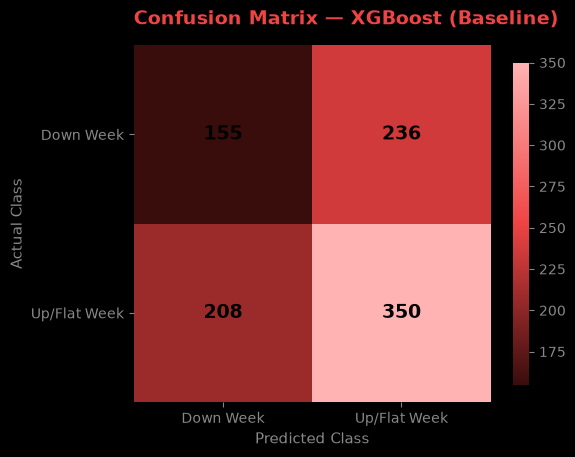

In [50]:
plt.close('all')

cm = confusion_matrix(y_test, y_pred_test)

#Red scale: dark red (low) to bright red (high), staying within the red family
red_cmap = mcolors.LinearSegmentedColormap.from_list("red_scale", ["#3a0d0d", "#EF4444", "#ffb3b3"])

fig, ax = plt.subplots(figsize=(6, 5))
fig.patch.set_facecolor("#000000")
ax.set_facecolor("#000000")

im = ax.imshow(cm, cmap=red_cmap)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                fontsize=14, fontweight='bold', color='#000000')

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Down Week", "Up/Flat Week"], color="#888888", fontsize=10)
ax.set_yticklabels(["Down Week", "Up/Flat Week"], color="#888888", fontsize=10)
ax.set_title(f'Confusion Matrix — {best_model_name}', fontsize=14, fontweight='bold', color="#EF4444", loc='left', pad=15)
ax.set_xlabel('Predicted Class', fontsize=11, color="#888888")
ax.set_ylabel('Actual Class', fontsize=11, color="#888888")
ax.tick_params(colors="#888888")
for spine in ax.spines.values():
    spine.set_visible(False)

cbar = plt.colorbar(im, ax=ax, shrink=0.8)
cbar.ax.yaxis.set_tick_params(color="#888888")
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color="#888888")
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()

The confusion matrix above shows how the model's predictions break down by actual outcome. Given the class imbalance in the target (more up/flat weeks than down weeks) and the fact that the model doesn't clearly beat a majority-class baseline in aggregate, it's worth reading this chart critically rather than as confirmation of skill: check whether the model is meaningfully separating the two classes, or largely defaulting toward the majority class regardless of input. A model that leans heavily toward predicting up/flat weeks will show strong recall on that class but a correspondingly high false-negative count on down weeks — worth weighing against the majority-baseline comparison above before treating this as evidence of real predictive value.

### Feature Importance

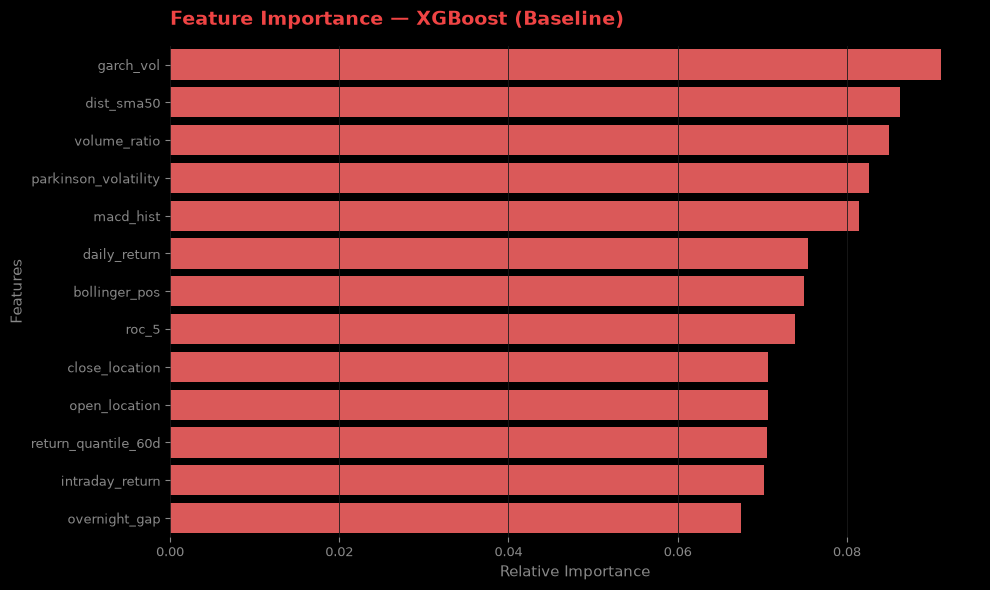

In [51]:
importances = pd.Series(final_model.feature_importances_, index=features).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor("#000000")
ax.set_facecolor("#000000")

sns.barplot(x=importances.values, y=importances.index, color='#EF4444', ax=ax)

ax.set_title(f'Feature Importance — {best_model_name}', fontsize=14, fontweight='bold', color="#EF4444", pad=15, loc='left')
ax.set_xlabel('Relative Importance', fontsize=11, color="#888888")
ax.set_ylabel('Features', fontsize=11, color="#888888")
ax.tick_params(labelsize=9, colors="#888888")
ax.grid(color="#1a1a1a", linewidth=0.6, axis='x')
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

Feature importance in the selected XGBoost model is spread fairly evenly across the feature set. `garch_vol` ranks first, but only slightly ahead of `dist_sma50`, `volume_ratio`, `parkinson_volatility` and `macd_hist`, and no single feature dominates the model's decisions. Its contribution was checked directly with a multi-seed ablation: the same model, with the same hyperparameters and sample weights, was retrained with and without `garch_vol` over five random seeds. Including it raises mean validation Class-1 F1 from 0.542 to 0.550 (+0.008), but the gain appears in only 3 of 5 seeds, and two seeds show essentially no difference. The gap is therefore within normal seed-to-seed noise rather than a confirmed improvement. Its standalone information coefficient with the target is also weak, so `garch_vol`'s top ranking should be read as a mild, unconfirmed contribution rather than evidence of a strong predictor.

The GARCH feature still carries specific operational risks worth flagging: refit non-convergence on new data, or a volatility regime the training history didn't cover. Because importance is not concentrated in it, and the ablation shows little loss without it, the model is less exposed to these failure modes than a model that relied heavily on one feature would be, but the dependency is not zero. A natural next step would be adding a fallback volatility estimator (such as `parkinson_volatility`, already in the feature set and ranked close behind) that the pipeline could rely on if `garch_vol` becomes unavailable, fails to converge, or drifts out of the regime it was estimated on.

### Backtest — Testing Real-World Value

Beyond classification metrics, the real question this project set out to answer is practical: **can the model help time entries better than a naive fixed-schedule investor?** To test this, two strategies are compared over the test period, both investing the same total capital in the same number of purchases:

- **Fixed Investor:** buys on a rigid schedule at evenly spaced intervals (every 12 trading days over this test period), regardless of any signal.
- **Smart Investor:** buys the same number of times, but each purchase is timed to the first day the model predicts an up/flat week with high confidence (P ≥ 0.60 or P ≥ 0.65, tested separately), falling back to a fixed day if no confident signal appears within a short window — so a purchase is never indefinitely delayed.

The comparison is evaluated on average price paid per share and overall ROI, which together show whether the model's predictions translate into a genuinely better investment outcome, not just a better classification score.

In [52]:

val_dates    = X_val.index
val_prices   = data.loc[val_dates, 'close']
y_proba_val  = pd.Series(final_model.predict_proba(X_val)[:, 1], index=val_dates)

N_PURCHASES_VAL = 75
FLEX_WINDOW = 5

n_val_days = len(val_dates)
interval_val = n_val_days // N_PURCHASES_VAL
due_indices_val = [min(i * interval_val, n_val_days - 1) for i in range(N_PURCHASES_VAL)]

def run_fixed_strategy(due_indices, dates, prices):
    purchase_dates = dates[due_indices]
    prices_paid = prices.iloc[due_indices]
    return purchase_dates, prices_paid

def run_smart_strategy(due_indices, dates, prices, proba, threshold, flex_window):
    n = len(dates)
    purchase_dates = []
    prices_paid = []
    for due in due_indices:
        window_start = max(due - flex_window, 0)
        window_end   = min(due + flex_window, n - 1)
        chosen = None
        for j in range(window_start, window_end + 1):
            if proba.iloc[j] >= threshold:
                chosen = j
                break
        if chosen is None:
            chosen = due
        purchase_dates.append(dates[chosen])
        prices_paid.append(prices.iloc[chosen])
    return pd.DatetimeIndex(purchase_dates), pd.Series(prices_paid, index=purchase_dates)

threshold_results = {}
for threshold in [0.60, 0.65]:
    _, smart_prices_val = run_smart_strategy(
        due_indices_val, val_dates, val_prices, y_proba_val, threshold, FLEX_WINDOW
    )
    avg_price = smart_prices_val.mean()
    threshold_results[threshold] = avg_price
    print(f"Threshold {threshold}: avg price paid on VALIDATION = ${avg_price:.2f}")

best_threshold = min(threshold_results, key=threshold_results.get)
print(f"\nSelected threshold (chosen on validation, applied to test below): {best_threshold}")


# STEP 2: Apply the selected threshold to the TEST period, exactly once


test_dates    = X_test.index
close_prices  = data.loc[test_dates, 'close']
y_proba_test  = pd.Series(final_model.predict_proba(X_test)[:, 1], index=test_dates)

N_PURCHASES  = 75
INVEST_AMOUNT = 1000

n_test_days = len(test_dates)
interval = n_test_days // N_PURCHASES

print(f"\nTest period: {n_test_days} days | N={N_PURCHASES} purchases | interval={interval} days | flex=±{FLEX_WINDOW} days")

due_indices = [min(i * interval, n_test_days - 1) for i in range(N_PURCHASES)]

fixed_dates, fixed_prices = run_fixed_strategy(due_indices, test_dates, close_prices)

smart_dates, smart_prices = run_smart_strategy(
    due_indices, test_dates, close_prices, y_proba_test, best_threshold, FLEX_WINDOW
)

print(f"Fixed Investor purchases: {len(fixed_prices)}")
print(f"Smart Investor (P >= {best_threshold}) purchases: {len(smart_prices)}")

assert len(fixed_prices) == len(smart_prices) == N_PURCHASES, "Purchase counts don't match!"


# COMPARISON METRICS


def summarize_strategy(name, prices_paid, invest_amount):
    total_invested = invest_amount * len(prices_paid)
    shares_bought  = (invest_amount / prices_paid).sum()
    avg_price      = prices_paid.mean()
    final_price    = close_prices.iloc[-1]
    final_value    = shares_bought * final_price
    roi_pct        = (final_value - total_invested) / total_invested * 100
    return {
        "Strategy": name,
        "Purchases": len(prices_paid),
        "Avg Price Paid": round(avg_price, 2),
        "Total Invested": round(total_invested, 2),
        "Shares Accumulated": round(shares_bought, 4),
        "Final Value": round(final_value, 2),
        "ROI (%)": round(roi_pct, 2),
    }

results = pd.DataFrame([
    summarize_strategy("Fixed Investor (evenly spaced)", fixed_prices, INVEST_AMOUNT),
    summarize_strategy(f"Smart Investor (P >= {best_threshold})", smart_prices, INVEST_AMOUNT),
]).set_index("Strategy")

results

Threshold 0.6: avg price paid on VALIDATION = $90.64
Threshold 0.65: avg price paid on VALIDATION = $90.47

Selected threshold (chosen on validation, applied to test below): 0.65

Test period: 949 days | N=75 purchases | interval=12 days | flex=±5 days
Fixed Investor purchases: 75
Smart Investor (P >= 0.65) purchases: 75


,Purchases,Avg Price Paid,Total Invested,Shares Accumulated,Final Value,ROI (%)
Strategy,,,,,,
Fixed Investor (evenly spaced),75,226.96,75000,392.2279,220114.36,193.49
Smart Investor (P >= 0.65),75,225.43,75000,393.7720,220980.93,194.64


In [53]:
#GARCH ablation: retrain the SELECTED final model (same type, same hyperparameters,
#same sample weights) with and without garch_vol, over several random seeds.
#Comparing the gap to the seed-to-seed spread shows whether it exceeds normal noise.

features_no_garch = [f for f in features if f != 'garch_vol']
SEEDS = [1, 2, 3, 4, 5]

def fit_and_score(feature_list, seed):
    params = final_model.get_params()
    params['random_state'] = seed
    m = type(final_model)(**params)
    m.fit(X_train[feature_list], y_train, sample_weight=sample_weights)
    return f1_score(y_val, m.predict(X_val[feature_list]), pos_label=1)

ablation = pd.DataFrame({
    "With garch_vol":    [fit_and_score(features, s) for s in SEEDS],
    "Without garch_vol": [fit_and_score(features_no_garch, s) for s in SEEDS],
}, index=[f"seed {s}" for s in SEEDS])
ablation["Gap"] = ablation["With garch_vol"] - ablation["Without garch_vol"]

print(f"Model: {best_model_name}")
print(f"Mean Class-1 F1 with garch_vol:    {ablation['With garch_vol'].mean():.3f} (std {ablation['With garch_vol'].std():.3f})")
print(f"Mean Class-1 F1 without garch_vol: {ablation['Without garch_vol'].mean():.3f} (std {ablation['Without garch_vol'].std():.3f})")
print(f"Mean gap: {ablation['Gap'].mean():+.3f} | gap positive in {(ablation['Gap'] > 0).sum()}/{len(SEEDS)} seeds")

ablation.round(3)

Model: XGBoost (Baseline)
Mean Class-1 F1 with garch_vol:    0.550 (std 0.004)
Mean Class-1 F1 without garch_vol: 0.542 (std 0.009)
Mean gap: +0.008 | gap positive in 3/5 seeds


,With garch_vol,Without garch_vol,Gap
seed 1,0.546,0.547,-0.001
seed 2,0.556,0.533,0.023
seed 3,0.547,0.533,0.014
seed 4,0.548,0.544,0.004
seed 5,0.552,0.552,-0.000


/var/folders/25/w29tdxyn7038m4w51t30kkgh0000gn/T/ipykernel_42107/1818320816.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=strategies, y=avg_prices, palette=colors, ax=ax, width=0.5)
findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


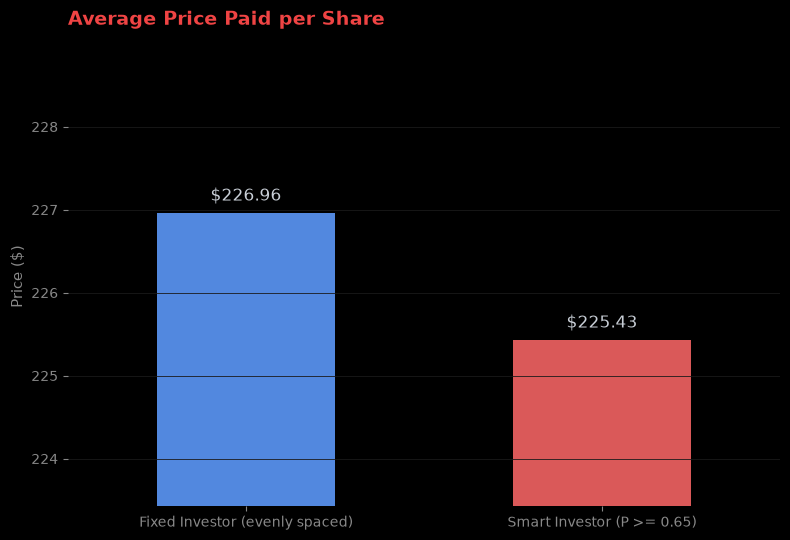

In [54]:
strategies = list(results.index)
avg_prices = results["Avg Price Paid"].tolist()
colors = ["#3B82F6", "#EF4444"]

fig, ax = plt.subplots(figsize=(8, 5.5))
fig.patch.set_facecolor("#000000")
ax.set_facecolor("#000000")

sns.barplot(x=strategies, y=avg_prices, palette=colors, ax=ax, width=0.5)

y_min = min(avg_prices) - 2
y_max = max(avg_prices) + 2
ax.set_ylim(y_min, y_max)

for i, v in enumerate(avg_prices):
    ax.text(i, v + 0.15, f"${v:.2f}", ha='center', fontsize=12, fontweight='medium', color="#c8ced6")

ax.set_title("Average Price Paid per Share", fontsize=14, fontweight='bold', color="#EF4444", pad=16, loc='left')
ax.set_ylabel("Price ($)", fontsize=11, color="#888888")
ax.set_xlabel("")
ax.tick_params(labelsize=10, colors="#888888")
ax.grid(color="#1a1a1a", linewidth=0.6, axis='y')
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

### Confidence-Weighted Position Sizing (Tiered) — Annual Capital Tranches, Guaranteed Deployment

The $100,000 capital pool is split into five annual tranches (one per year in the test period), and each strategy must spend its full share within that year — unused money does not roll over. 

Each scheduled purchase date works like this: the model checks that day's confidence level first. If it's not high enough to qualify, the simulated investor simply **waits and checks again the next day**, for up to a few days, until either a confident signal appears or the short waiting window runs out. This mirrors how a real investor would actually behave — checking in day by day, never knowing in advance what a future day's signal will look like, only finding out once that day actually arrives. 

When a qualifying day is found, the purchase is sized based on how confident the model was that day (a small, medium, or large percentage of that year's budget). If the waiting window runs out with no qualifying day, a small default purchase is made instead, so no opportunity is skipped entirely. Any shortfall in spending is spread evenly across the year's remaining purchases, rather than dumped into a single trade, so the full budget is always used by year's end without any one purchase carrying outsized risk.

### Confidence-Tiered Position Sizing — Exploratory, Not Statistically Confirmed

The confidence-tier check above tested whether higher stated model confidence corresponds to higher actual accuracy, using validation data across three candidate thresholds, each with a 95% confidence interval. It found no such relationship. Precision does not rise with the threshold: 0.539 at P ≥ 0.60 (n = 243), 0.504 at P ≥ 0.65 (n = 135) and 0.562 at P ≥ 0.70 (n = 73). All three are below the validation base rate of 0.578, and every interval contains it. At this sample size, none of the tiers can be distinguished from chance: the days the model is confident about are not up/flat weeks more often than an average day.

Given that, the tiered position-sizing strategy below is presented as **exploratory rather than validated**. It runs under the assumption that model confidence reflects entry quality, which the check above does not support. It demonstrates how the pipeline would scale capital allocation with model confidence if a real confidence-accuracy relationship emerges (with more data, a longer history, or model improvements), rather than a scheme confirmed to add value today. The specific thresholds and allocation weights used below are illustrative design choices, not cutoffs supported by the evidence above. The random-timing benchmark after the backtest tests directly whether the model's signal contributes anything to the tiered result.

In [55]:
y_proba_val_check = pd.Series(final_model.predict_proba(X_val)[:, 1], index=X_val.index)

tier_bounds = [0.60, 0.65, 0.70]
base_rate = y_val.mean()

print(f"Validation base rate (class 1): {base_rate:.3f}\n")
print(f"{'Tier':<12}{'n':<8}{'Precision':<12}{'95% CI':<20}")

for lower in tier_bounds:
    mask = y_proba_val_check >= lower
    n = mask.sum()
    if n == 0:
        print(f"P>={lower:<8}{n:<8}{'--':<12}{'--':<20}{'no data'}")
        continue

    correct = y_val[mask].sum()
    precision = correct / n

    #Wilson score interval (more reliable than normal approx at small n)
    ci = binomtest(int(correct), int(n)).proportion_ci(confidence_level=0.95, method='wilson')
    lo, hi = ci.low, ci.high


    print(f"P>={lower:<8}{n:<8}{precision:<12.3f}[{lo:.3f}, {hi:.3f}]")

Validation base rate (class 1): 0.578

Tier        n       Precision   95% CI              
P>=0.6     243     0.539       [0.476, 0.601]
P>=0.65    135     0.504       [0.420, 0.587]
P>=0.7     73      0.562       [0.448, 0.670]


In [56]:
#Tiered Sizing — Annual Capital Tranches (Guaranteed Deployment)

TOTAL_CAPITAL = 100_000   #total capitalto invest
P_MIN = 0.60               #minimum confidence to qualify for tiered sizing
FLEX_WINDOW_CAP = 3        #smart investor may shift ±3 days around each due date to avoid impulsive buys
INTERVAL_DAYS = 6          #a new purchase opportunity every 6 trading days

def confidence_to_position_size_tiered(proba, annual_budget):
    #Maps model confidence to a purchase size, as a % of THAT YEAR's budget.
    
    if proba >= 0.70:
        return 0.12 * annual_budget    #high conviction: 12%
    elif proba >= 0.65:
        return 0.07 * annual_budget    #confident: 7%
    elif proba >= 0.60:
        return 0.03 * annual_budget    #moderate: 3%
    else:
        return 0

def run_smart_tiered_guaranteed(dates, prices, proba, flex_window, budget, p_min):
    n = len(dates)
    due_indices = list(range(0, n, INTERVAL_DAYS))
    purchase_dates, prices_paid, amounts_invested = [], [], []
    capital_left = budget
    remaining_windows = len(due_indices)

    for due in due_indices:
        if capital_left <= 0:
            break

        #Scan FORWARD ONLY from the due date -- no peeking at future-relative days
        #that haven't "happened" yet in the simulation's timeline.
        window_end = min(due + flex_window, n - 1)
        chosen, chosen_proba = None, None
        for j in range(due, window_end + 1):
            if proba.iloc[j] >= p_min:
                chosen, chosen_proba = j, proba.iloc[j]
                break  #first qualifying day, not the "best" one -- no hindsight

        if chosen is None:
            #No qualifying day found while scanning forward -- fall back to
            #the original due date, buy a small, minimum-tier amount.
            chosen, chosen_proba = due, proba.iloc[due]
            amount = min(0.01 * budget, capital_left)
        else:
            amount = min(confidence_to_position_size_tiered(chosen_proba, budget), capital_left)

        fair_share_remaining = capital_left / remaining_windows
        amount = max(amount, min(fair_share_remaining, capital_left))

        purchase_dates.append(dates[chosen])
        prices_paid.append(prices.iloc[chosen])
        amounts_invested.append(amount)
        capital_left -= amount
        remaining_windows -= 1

    return (pd.DatetimeIndex(purchase_dates),
            pd.Series(prices_paid, index=purchase_dates),
            pd.Series(amounts_invested, index=purchase_dates))

            
#--- Split test period into years ---
test_data = data.loc[test_dates].copy()
test_data['year'] = test_data.index.year
years = sorted(test_data['year'].unique())
annual_budget = TOTAL_CAPITAL / len(years)   #equal budget for every year

print(f"Test period spans {len(years)} years: {years}")
print(f"Annual budget per strategy: ${annual_budget:,.2f}\n")

all_smart_dates, all_smart_prices, all_smart_amounts = [], [], []
all_fixed_dates, all_fixed_prices, all_fixed_amounts = [], [], []

for year in years:
    #Isolate this year's dates, prices, and model predictions.
    year_mask = test_data['year'] == year
    year_dates = test_data.index[year_mask]
    year_prices = test_data.loc[year_dates, 'close']
    year_proba = y_proba_test.loc[year_dates]

    #Run the smart investor for this year's $20k budget only (no carryover).
    s_dates, s_prices, s_amounts = run_smart_tiered_guaranteed(
        year_dates, year_prices, year_proba, FLEX_WINDOW_CAP, annual_budget, P_MIN
    )
    all_smart_dates.append(s_dates)
    all_smart_prices.append(s_prices)
    all_smart_amounts.append(s_amounts)

    #Fixed investor: TRUE fixed dates (every INTERVAL_DAYS, no flex, no signal check).
    #Total capital matched to what the smart investor actually spent this year
    #(which is always the full $20k, since deployment is guaranteed above).
    year_spent = s_amounts.sum()
    n_fixed_purchases = max(len(year_dates) // INTERVAL_DAYS, 1)
    f_due = [min(i * INTERVAL_DAYS, len(year_dates) - 1) for i in range(n_fixed_purchases)]
    f_dates = year_dates[f_due]
    f_prices = year_prices.iloc[f_due]
    f_amounts = pd.Series(year_spent / n_fixed_purchases, index=f_dates)

    all_fixed_dates.append(f_dates)
    all_fixed_prices.append(f_prices)
    all_fixed_amounts.append(f_amounts)

    print(f"{year}: Smart spent ${year_spent:,.2f} of ${annual_budget:,.2f} ({year_spent/annual_budget*100:.1f}%) in {len(s_dates)} purchases")

#--- Combine all years into one continuous record per strategy ---
smart_prices_cap  = pd.concat(all_smart_prices)
smart_amounts_cap = pd.concat(all_smart_amounts)
fixed_prices_cap  = pd.concat(all_fixed_prices)
fixed_amounts_cap = pd.concat(all_fixed_amounts)

print(f"\nSmart investor total: {len(smart_prices_cap)} purchases | ${smart_amounts_cap.sum():,.2f} deployed ({smart_amounts_cap.sum()/TOTAL_CAPITAL*100:.1f}%)")
print(f"Fixed investor total:  {len(fixed_prices_cap)} purchases | ${fixed_amounts_cap.sum():,.2f} deployed")

def summarize_capital_strategy(name, prices_paid, amounts_invested):
    #Computes shares bought, dollar-weighted avg price, final value, and ROI.
    shares_bought  = (amounts_invested / prices_paid).sum()
    total_invested = amounts_invested.sum()
    final_price    = close_prices.iloc[-1]
    final_value    = shares_bought * final_price
    roi_pct        = (final_value - total_invested) / total_invested * 100
    return {
        "Strategy": name,
        "Purchases": len(prices_paid),
        "Total Invested": round(total_invested, 2),
        "Avg Price Paid": round((prices_paid * amounts_invested).sum() / amounts_invested.sum(), 2),
        "Shares Accumulated": round(shares_bought, 4),
        "Final Value": round(final_value, 2),
        "ROI (%)": round(roi_pct, 2),
    }

results_capital_annual = pd.DataFrame([
    summarize_capital_strategy("Fixed Investor (annual tranches)", fixed_prices_cap, fixed_amounts_cap),
    summarize_capital_strategy("Smart Investor (annual tranches, tiered)", smart_prices_cap, smart_amounts_cap),
]).set_index("Strategy")

results_capital_annual

Test period spans 5 years: [np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]
Annual budget per strategy: $20,000.00

2022: Smart spent $20,000.00 of $20,000.00 (100.0%) in 10 purchases
2023: Smart spent $20,000.00 of $20,000.00 (100.0%) in 22 purchases
2024: Smart spent $20,000.00 of $20,000.00 (100.0%) in 25 purchases
2025: Smart spent $20,000.00 of $20,000.00 (100.0%) in 16 purchases
2026: Smart spent $20,000.00 of $20,000.00 (100.0%) in 23 purchases

Smart investor total: 96 purchases | $100,000.00 deployed (100.0%)
Fixed investor total:  156 purchases | $100,000.00 deployed


,Purchases,Total Invested,Avg Price Paid,Shares Accumulated,Final Value,ROI (%)
Strategy,,,,,,
Fixed Investor (annual tranches),156,100000.0,244.99,556.3592,312223.20,212.22
"Smart Investor (annual tranches, tiered)",96,100000.0,222.80,596.8015,334919.02,234.92


In [57]:
#Build growth series using a proper running-share method

def cumulative_value_correct(prices_paid, amounts_invested, price_series, all_dates):
    shares_bought = (amounts_invested / prices_paid).sort_index()
    shares_cum = shares_bought.cumsum()
    shares_on_each_day = shares_cum.reindex(all_dates, method='ffill').fillna(0)
    portfolio_value = shares_on_each_day * price_series.reindex(all_dates)
    return portfolio_value.fillna(0)

all_dates = sorted(set(test_dates))
fixed_growth = cumulative_value_correct(fixed_prices_cap, fixed_amounts_cap, close_prices, all_dates)
smart_growth = cumulative_value_correct(smart_prices_cap, smart_amounts_cap, close_prices, all_dates)


#Correct return calculation: portfolio value vs. cumulative capital invested
#(NOT vs. the first purchase -- that's wrong for a recurring-investment strategy)

def cumulative_invested(amounts_invested, all_dates):
    invested_cum = amounts_invested.sort_index().cumsum()
    return invested_cum.reindex(all_dates, method='ffill').fillna(0)

fixed_invested_cum = cumulative_invested(fixed_amounts_cap, all_dates)
smart_invested_cum = cumulative_invested(smart_amounts_cap, all_dates)

fixed_pct_return = ((fixed_growth - fixed_invested_cum) / fixed_invested_cum.replace(0, np.nan) * 100).fillna(0)
smart_pct_return = ((smart_growth - smart_invested_cum) / smart_invested_cum.replace(0, np.nan) * 100).fillna(0)

print(f"Fixed final value: ${fixed_growth.iloc[-1]:,.2f}")
print(f"Smart final value: ${smart_growth.iloc[-1]:,.2f}")
print(f"Fixed pct return range: {fixed_pct_return.min():.2f}% to {fixed_pct_return.max():.2f}%")
print(f"Smart pct return range: {smart_pct_return.min():.2f}% to {smart_pct_return.max():.2f}%")
print(f"Fixed final return: {fixed_pct_return.iloc[-1]:.2f}%")
print(f"Smart final return: {smart_pct_return.iloc[-1]:.2f}%")

Fixed final value: $312,223.20
Smart final value: $334,919.02
Fixed pct return range: -1.93% to 279.11%
Smart pct return range: -0.20% to 302.52%
Fixed final return: 212.22%
Smart final return: 234.92%


In [58]:
plt.rcParams['animation.embed_limit'] = 50  # <-- add this line

fig, ax = plt.subplots(figsize=(12, 6.5))
fig.patch.set_facecolor("#000000")
ax.set_facecolor("#000000")

n_frames = 300
sample_idx = np.linspace(0, len(all_dates) - 1, n_frames).astype(int)
LOOKBACK = 35

line_fixed, = ax.plot([], [], color="#EEEEEE", linewidth=1.6, linestyle=(0, (4, 2)))
line_smart, = ax.plot([], [], color="#EF4444", linewidth=1.8)
dot_fixed = ax.scatter([], [], color="#EEEEEE", s=35, zorder=5)
dot_smart = ax.scatter([], [], color="#EF4444", s=35, zorder=5)
label_fixed = ax.text(0, 0, "", color="#EEEEEE", fontsize=9, va='bottom')
label_smart = ax.text(0, 0, "", color="#EF4444", fontsize=9, va='top')
gap_fill = [None]

ax.tick_params(colors="#888888", labelsize=9)
ax.grid(color="#1a1a1a", linewidth=0.6)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_ylabel("Return (%)", color="#888888", fontsize=10)

headline = ax.text(0.01, 1.10, "", transform=ax.transAxes, fontsize=15, fontweight='bold', color="#EF4444")
subtitle = ax.text(0.01, 1.03, "", transform=ax.transAxes, fontsize=10, color="#AAAAAA")

def update(frame):
    i = sample_idx[frame]
    x = all_dates[:i+1]
    yf = fixed_pct_return.values[:i+1]
    ys = smart_pct_return.values[:i+1]

    line_fixed.set_data(x, yf)
    line_smart.set_data(x, ys)

    if gap_fill[0] is not None:
        gap_fill[0].remove()
    gap_fill[0] = ax.fill_between(x, yf, ys, color="#EF4444", alpha=0.25, zorder=1)

    window_start = max(0, i - LOOKBACK)
    ax.set_xlim(all_dates[window_start], all_dates[min(i + 5, len(all_dates) - 1)])

    yf_window = yf[window_start:]
    ys_window = ys[window_start:]
    combined = np.concatenate([yf_window, ys_window])
    y_lo, y_hi = combined.min(), combined.max()
    pad = max((y_hi - y_lo) * 0.10, 0.03)
    ax.set_ylim(y_lo - pad, y_hi + pad)

    cur_date = all_dates[i]
    cur_f, cur_s = yf[-1], ys[-1]

    dot_fixed.set_offsets([[cur_date, cur_f]])
    dot_smart.set_offsets([[cur_date, cur_s]])
    label_fixed.set_position((cur_date, cur_f - pad*0.2))
    label_fixed.set_text(f"  Fixed {cur_f:.2f}%")
    label_smart.set_position((cur_date, cur_s + pad*0.2))
    label_smart.set_text(f"  Smart {cur_s:.2f}%")

    leader = "Smart Investor" if cur_s > cur_f else "Fixed Investor"
    headline.set_text(f"{cur_date.strftime('%Y-%m-%d')}  |  {leader} leads")
    subtitle.set_text(f"Fixed: {cur_f:.2f}%   |   Smart: {cur_s:.2f}%   |   Gap: {cur_s - cur_f:+.2f} pts")

    return line_fixed, line_smart, dot_fixed, dot_smart, label_fixed, label_smart, headline, subtitle, gap_fill[0]

ani = animation.FuncAnimation(fig, update, frames=len(sample_idx), interval=50, blit=False)
plt.close(fig)
HTML(ani.to_jshtml())

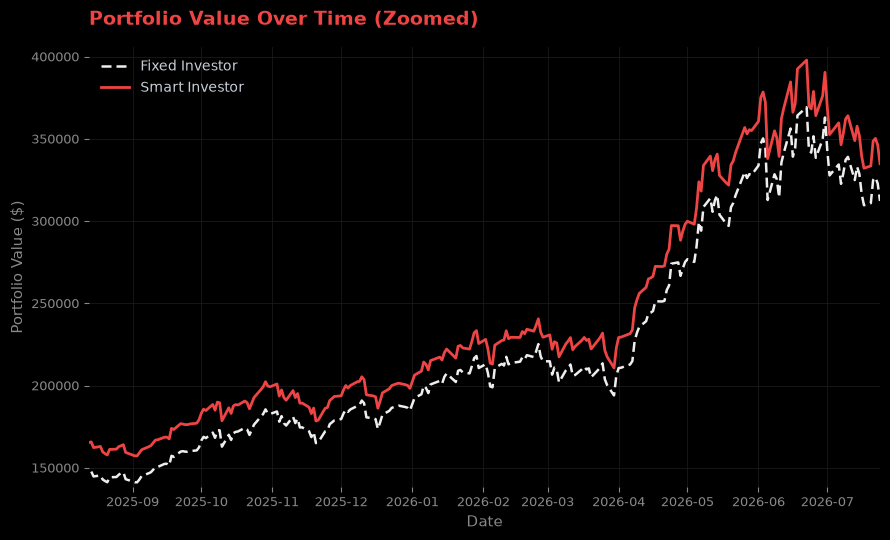

In [59]:
fig, ax = plt.subplots(figsize=(9, 5.5))
fig.patch.set_facecolor("#000000")
ax.set_facecolor("#000000")

ax.plot(all_dates, fixed_growth.values, color="#EEEEEE", linewidth=1.8, linestyle=(0, (4, 2)), label="Fixed Investor")
ax.plot(all_dates, smart_growth.values, color="#EF4444", linewidth=2, label="Smart Investor")

zoom_start = int(len(all_dates) * 0.75)
ax.set_xlim(all_dates[zoom_start], all_dates[-1])
y_slice_min = min(fixed_growth.values[zoom_start:].min(), smart_growth.values[zoom_start:].min()) * 0.98
y_slice_max = max(fixed_growth.values[zoom_start:].max(), smart_growth.values[zoom_start:].max()) * 1.02
ax.set_ylim(y_slice_min, y_slice_max)

ax.set_title("Portfolio Value Over Time (Zoomed)", fontsize=14, fontweight='bold', color="#EF4444", pad=16, loc='left')
ax.set_xlabel("Date", fontsize=11, color="#888888")
ax.set_ylabel("Portfolio Value ($)", fontsize=11, color="#888888")
ax.tick_params(labelsize=9, colors="#888888")
ax.grid(color="#1a1a1a", linewidth=0.6)
for spine in ax.spines.values():
    spine.set_visible(False)

legend = ax.legend(frameon=False, fontsize=10, loc='upper left')
for text in legend.get_texts():
    text.set_color("#c8ced6")

plt.tight_layout()
plt.show()

### Random-Timing Benchmark — Is the Model's Signal Driving the Tiered Result?

The tiered strategy outperformed the fixed-schedule investor, but that outperformance could come from two different sources:

1. **The model's signal** — confident days really are better days to buy, so sizing up on them pays off.
2. **The strategy's mechanics** — fewer, larger purchases and a different spending rhythm within each year (for example, using up the annual budget earlier), which could beat a fixed schedule in a trending market regardless of any signal.

The confidence-tier check above could not confirm (1), so this benchmark tests it directly with a **permutation test**:

- Within each year of the test period, the model's predicted probabilities are randomly **shuffled** across days. This keeps everything about the strategy identical — the same tiers, the same mix of confident and non-confident days, the same budget rules — but breaks the link between each day's probability and what actually happened on that day.
- The tiered strategy is re-run on the shuffled probabilities many times, producing a distribution of ROIs a *signal-free* version of the same strategy would achieve.
- The real model's ROI is then compared to that distribution.

**How to read the result:**
- **Fixed → random median:** the part of the outperformance explained by the strategy's mechanics alone.
- **Random median → model:** the part attributable to the model's signal.
- **Empirical p-value:** the share of random runs that matched or beat the model. Below 0.05 means the signal's contribution is unlikely to be luck.

In [60]:
N_SIMS = 500                    #number of shuffled runs
rng = np.random.default_rng(42) #fixed seed so the benchmark is reproducible

def run_tiered_all_years(proba_series):
    """Runs the tiered smart investor over every test year with the given
    probabilities and returns its purchases (same rules as the cell above)."""
    prices_list, amounts_list = [], []
    for year in years:
        year_dates  = test_data.index[test_data['year'] == year]
        year_prices = test_data.loc[year_dates, 'close']
        _, s_prices, s_amounts = run_smart_tiered_guaranteed(
            year_dates, year_prices, proba_series.loc[year_dates],
            FLEX_WINDOW_CAP, annual_budget, P_MIN
        )
        prices_list.append(s_prices)
        amounts_list.append(s_amounts)
    return pd.concat(prices_list), pd.concat(amounts_list)

def shuffle_within_year(proba):
    """Randomly reorders the probabilities inside each year: same values, random days."""
    shuffled = proba.copy()
    for year in years:
        mask = proba.index.year == year
        shuffled[mask] = rng.permutation(proba[mask].values)
    return shuffled

#Sanity check: the real probabilities must reproduce the tiered result above
p_model, a_model = run_tiered_all_years(y_proba_test)
model_roi = summarize_capital_strategy("model", p_model, a_model)["ROI (%)"]
fixed_roi = results_capital_annual.loc["Fixed Investor (annual tranches)", "ROI (%)"]
assert np.isclose(model_roi, results_capital_annual.loc["Smart Investor (annual tranches, tiered)", "ROI (%)"]), \
    "Benchmark does not reproduce the tiered result above -- check that the previous cells ran in order."

random_rois = []
for _ in range(N_SIMS):
    p_rand, a_rand = run_tiered_all_years(shuffle_within_year(y_proba_test))
    random_rois.append(summarize_capital_strategy("random", p_rand, a_rand)["ROI (%)"])
random_rois = np.array(random_rois)

random_median = np.median(random_rois)
percentile    = (random_rois < model_roi).mean() * 100
p_value       = (1 + (random_rois >= model_roi).sum()) / (N_SIMS + 1)

benchmark_df = pd.DataFrame({
    "ROI (%)": [fixed_roi, random_median, np.percentile(random_rois, 5),
                np.percentile(random_rois, 95), model_roi]
}, index=["Fixed Investor", "Random timing — median", "Random timing — 5th pct",
          "Random timing — 95th pct", "Model-driven (tiered)"]).round(2)

print(f"Random-timing runs: {N_SIMS}")
print(f"Outperformance vs fixed:          {model_roi - fixed_roi:+.2f} pts")
print(f"  explained by mechanics alone:   {random_median - fixed_roi:+.2f} pts (fixed -> random median)")
print(f"  attributable to model signal:   {model_roi - random_median:+.2f} pts (random median -> model)")
print(f"Model beats {percentile:.1f}% of random runs | empirical p-value = {p_value:.3f}\n")

if p_value < 0.05:
    verdict = ("The model-driven result beats at least 95% of signal-free runs: the timing signal "
               "contributes to the outperformance beyond what the strategy's mechanics explain.")
elif percentile >= 80:
    verdict = ("The model-driven result sits in the upper part of the random distribution: the signal "
               "appears to help, but not strongly enough to rule out luck at this sample size.")
else:
    verdict = ("The model-driven result is in line with signal-free runs: the outperformance vs. the fixed "
               "investor is explained mainly by the strategy's mechanics, not by the model's signal.")
print("Verdict:", verdict)

benchmark_df

Random-timing runs: 500
Outperformance vs fixed:          +22.70 pts
  explained by mechanics alone:   +23.47 pts (fixed -> random median)
  attributable to model signal:   -0.78 pts (random median -> model)
Model beats 40.8% of random runs | empirical p-value = 0.593

Verdict: The model-driven result is in line with signal-free runs: the outperformance vs. the fixed investor is explained mainly by the strategy's mechanics, not by the model's signal.


,ROI (%)
Fixed Investor,212.22
Random timing — median,235.70
Random timing — 5th pct,230.54
Random timing — 95th pct,239.88
Model-driven (tiered),234.92


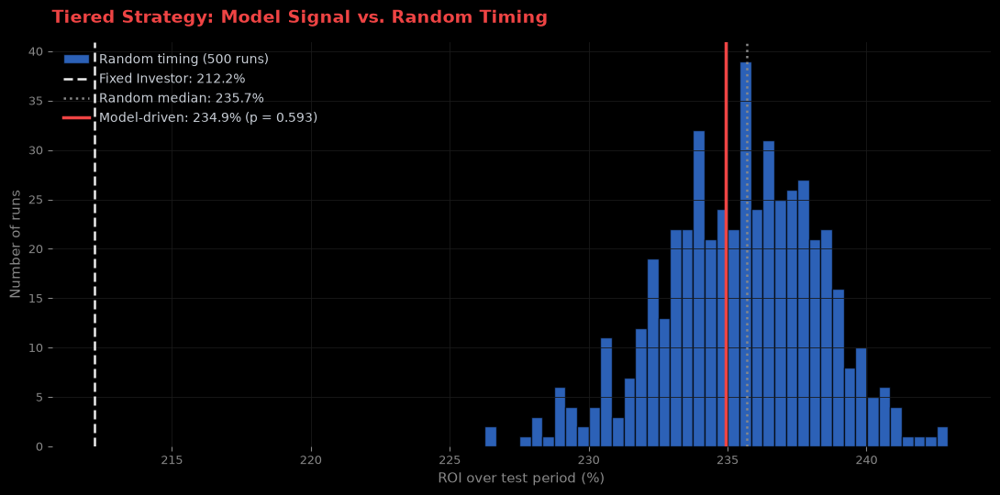

In [61]:
fig, ax = plt.subplots(figsize=(11, 5.5))
fig.patch.set_facecolor("#000000")
ax.set_facecolor("#000000")

ax.hist(random_rois, bins=40, color="#3B82F6", alpha=0.75, edgecolor="#000000",
        label=f"Random timing ({N_SIMS} runs)")
ax.axvline(fixed_roi, color="#EEEEEE", linestyle=(0, (4, 2)), linewidth=1.8,
           label=f"Fixed Investor: {fixed_roi:.1f}%")
ax.axvline(random_median, color="#888888", linestyle=":", linewidth=1.8,
           label=f"Random median: {random_median:.1f}%")
ax.axvline(model_roi, color="#EF4444", linewidth=2.5,
           label=f"Model-driven: {model_roi:.1f}% (p = {p_value:.3f})")

ax.set_title("Tiered Strategy: Model Signal vs. Random Timing", fontsize=14, fontweight='bold',
             color="#EF4444", pad=15, loc='left')
ax.set_xlabel("ROI over test period (%)", fontsize=11, color="#888888")
ax.set_ylabel("Number of runs", fontsize=11, color="#888888")
ax.tick_params(labelsize=9, colors="#888888")
ax.grid(color="#1a1a1a", linewidth=0.6)
for spine in ax.spines.values():
    spine.set_visible(False)

legend = ax.legend(frameon=False, fontsize=10, loc='upper left')
for text in legend.get_texts():
    text.set_color("#c8ced6")

plt.tight_layout()
plt.show()

### Spending Rhythm Diagnostic

One mechanical effect the benchmark above controls for is *when* within each year the money gets deployed. The tiered investor stops buying once its annual budget runs out, while the fixed investor spreads purchases evenly across the whole year. The table below shows, for each year, the dollar-weighted average month of purchase and the share of the budget deployed by the end of the first quarter. In a year where prices rise steadily, spending earlier lowers the average price paid regardless of any signal; in a falling year, it does the opposite. The 2022 row covers only the last months of that year (the start of the test period), so both strategies show the same timing there.

In [62]:
def spending_profile(amounts):
    df = pd.DataFrame({"amount": amounts.values}, index=amounts.index)
    df["year"], df["month"] = df.index.year, df.index.month
    rows = []
    for year, g in df.groupby("year"):
        rows.append({
            "Year": year,
            "Avg month (weighted)": round((g["month"] * g["amount"]).sum() / g["amount"].sum(), 1),
            "% deployed by end of Q1": round(g.loc[g["month"] <= 3, "amount"].sum() / g["amount"].sum() * 100, 1),
        })
    return pd.DataFrame(rows).set_index("Year")

spending_df = pd.concat(
    {"Fixed": spending_profile(fixed_amounts_cap), "Tiered (model)": spending_profile(smart_amounts_cap)},
    axis=1
)
spending_df

Fixed                               Tiered (model)  \
     Avg month (weighted) % deployed by end of Q1 Avg month (weighted)   
Year                                                                     
2022                 11.0                     0.0                 11.0   
2023                  6.3                    26.8                  3.2   
2024                  6.4                    26.2                  4.1   
2025                  6.4                    24.4                  3.1   
2026                  3.8                    47.8                  3.4   

                              
     % deployed by end of Q1  
Year                          
2022                     0.0  
2023                    55.1  
2024                    39.7  
2025                    52.1  
2026                    60.7

### Backtest Summary

Two backtest designs were tested against a fixed-schedule baseline, both corrected to ensure the simulated investor only acts on information available at the time of each decision (no forward-looking day selection).

The simple, single-threshold strategy varies only purchase timing. Its confidence threshold (P ≥ 0.65) was selected on validation data before a single, final test-set evaluation. On test it edged out the fixed-schedule baseline only slightly: an average price paid of \$225.43 vs. \$226.96, and an ROI of 194.64% vs. 193.49% (+1.15 points). The procedure is sound, but the edge is small enough that it should not be read as strong evidence of timing skill.

The tiered, confidence-weighted strategy varies both timing and position size, with capital deployed in annual tranches. It is an experiment under the assumption that model confidence reflects entry quality. It beat the fixed investor by 22.70 ROI points (234.92% vs. 212.22%), but the random-timing benchmark shows this outperformance does not come from the model: signal-free runs of the same strategy, with probabilities shuffled within each year, reach a median ROI of 235.70%. The strategy's mechanics, chiefly deploying more of each year's budget earlier in a rising market, explain +23.47 points, while the model's signal adds −0.78 points (the model beats 40.8% of random runs; empirical p-value = 0.593). This is consistent with the confidence-tier check, which found no relationship between model confidence and accuracy.

Taken together, the two backtests do not show a reliable timing edge from the model over this test period: the simple strategy's gain is marginal, and the tiered strategy's gain is explained by when it spends rather than by what the model predicts. The tiered design remains a usable framework if a stronger signal is found, but these results do not confirm its value.

# References



Investopedia. (2024). Technical analysis. https://www.investopedia.com/technical-analysis-4689657



Murphy, J. (2024). Moving averages: Simple and exponential. StockCharts ChartSchool. https://chartschool.stockcharts.com/table-of-contents/technical-indicators-and-overlays/technical-overlays/moving-averages-simple-and-exponential



ChartingLens. (2026). RSI, MACD & Bollinger Bands: Complete guide to technical indicators. https://chartinglens.com/blog/rsi-macd-bollinger-bands-guide



Gao, Y., et al. (2024). Multi-source information fusion for stock market prediction using machine learning. Information Fusion, 108. https://doi.org/10.1016/j.inffus.2024.102369
